# 🏡 End-to-End House Price Prediction Pipeline
**Author / Data Scientist:** (Your Name)

## 📌 Executive Summary
This notebook represents a comprehensive, end-to-end Machine Learning pipeline. Predicting house prices is a classic regression problem, but real-world housing data is incredibly messy. 

In this project, we tackle the **Ames Housing Dataset**, which contains 79 explanatory variables describing almost every aspect of residential homes. The goal of this notebook is not just to fit a model, but to demonstrate a complete, professional **Data Science Lifecycle**:

1. **Extensive Exploratory Data Analysis (EDA):** Discovering patterns, correlations, and anomalies.
2. **Robust Data Preprocessing:** Handling missing values, encoding hierarchical categories, and removing statistical outliers.
3. **Feature Engineering:** Applying mathematical transformations (like Log1p) to normalize highly skewed variables and the target price.
4. **Model Selection & Comparison:** Training and evaluating 6 different algorithms (ranging from baseline Linear Regression to advanced Gradient Boosting) to identify the absolute best predictive model.

Let's dive in!\n

# Comprehensive Housing Dataset Exploratory Data Analysis

This notebook performs extensive Exploratory Data Analysis (EDA) on the Ames Housing dataset, evaluating feature correlations and preparing data for predictive modeling.

In [1]:
import pandas as pd

In [22]:
import matplotlib.pyplot as plt

In [5]:
df=pd.read_csv("train.csv")

In [6]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [8]:
df.shape

(1460, 81)

In [10]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [16]:
df.isnull().sum().head(30)

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
Street             0
Alley           1369
LotShape           0
LandContour        0
Utilities          0
LotConfig          0
LandSlope          0
Neighborhood       0
Condition1         0
Condition2         0
BldgType           0
HouseStyle         0
OverallQual        0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
RoofStyle          0
RoofMatl           0
Exterior1st        0
Exterior2nd        0
MasVnrType       872
MasVnrArea         8
ExterQual          0
ExterCond          0
Foundation         0
dtype: int64

<Axes: xlabel='Alley', ylabel='SalePrice'>

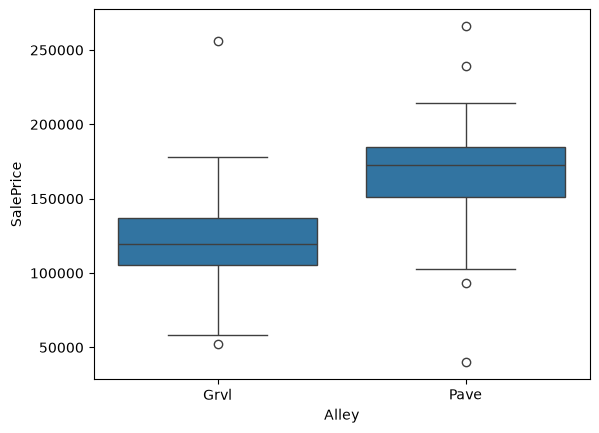

In [19]:
import seaborn as sns
sns.boxplot(x=df["Alley"], y=df["SalePrice"])


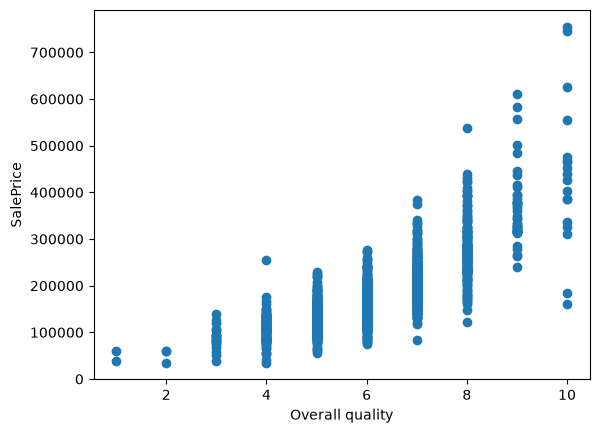

In [37]:
    plt.scatter(df["OverallQual"], df["SalePrice"])
    plt.xlabel("Overall quality")
    plt.ylabel("SalePrice")
    plt.show()

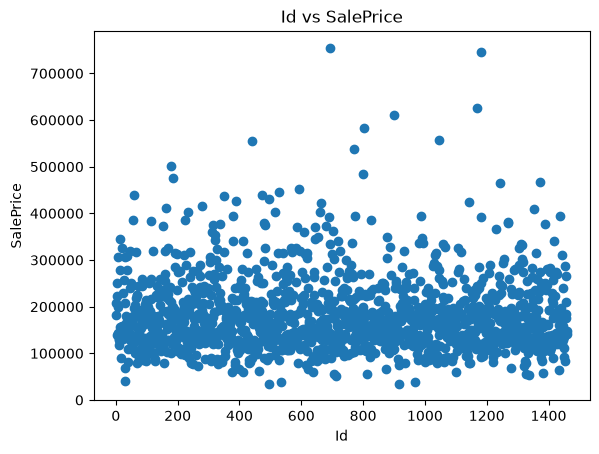

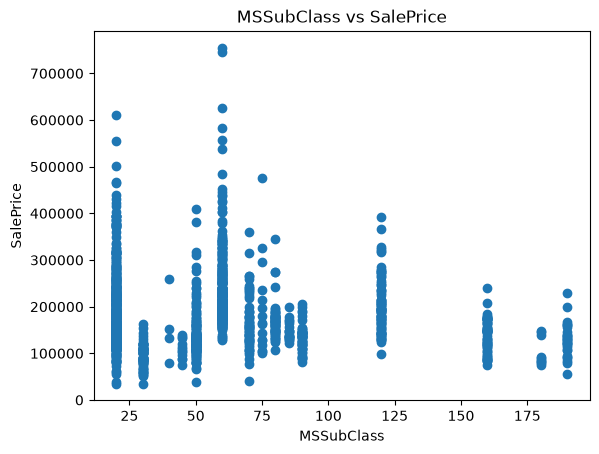

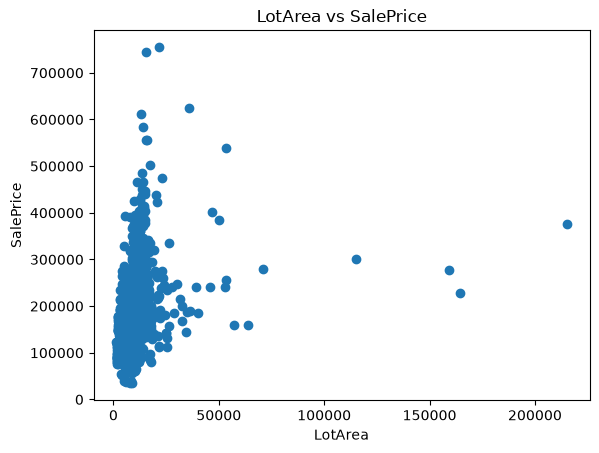

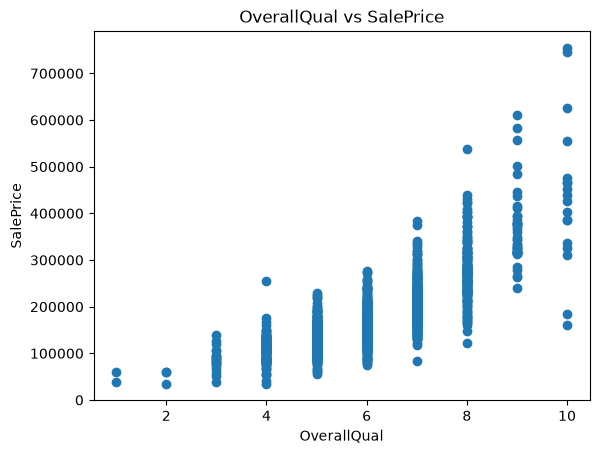

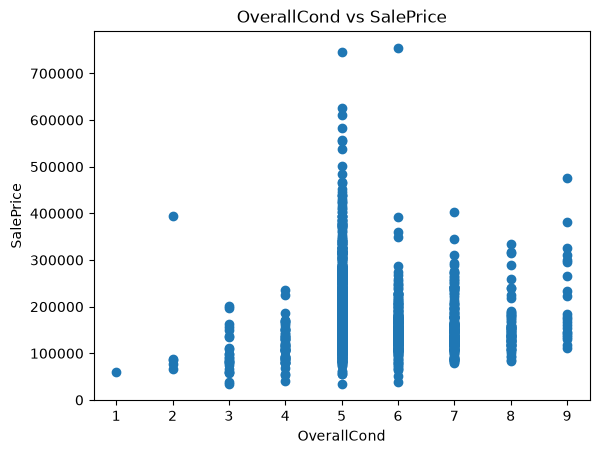

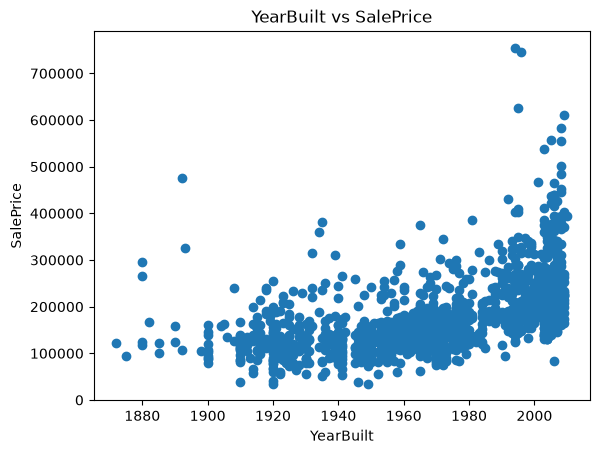

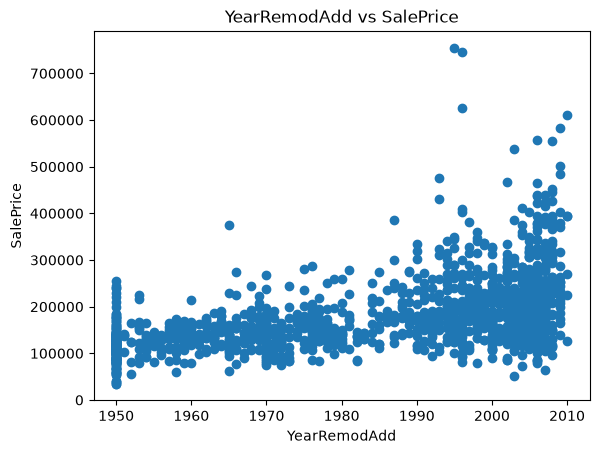

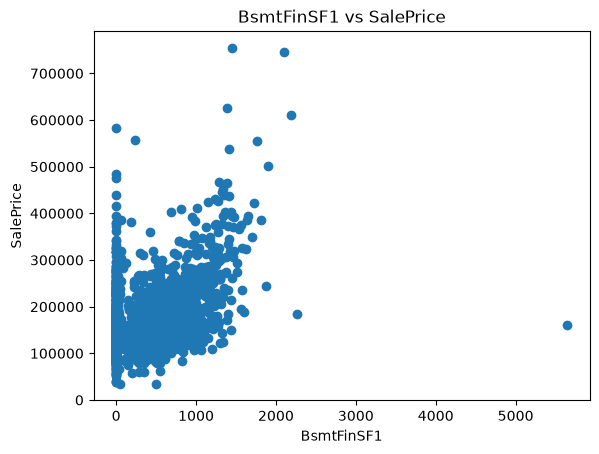

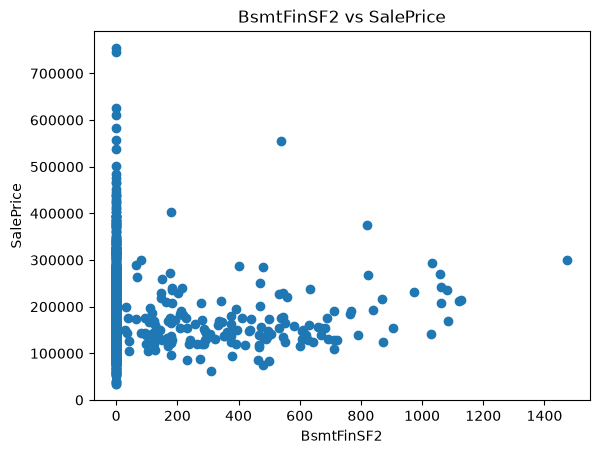

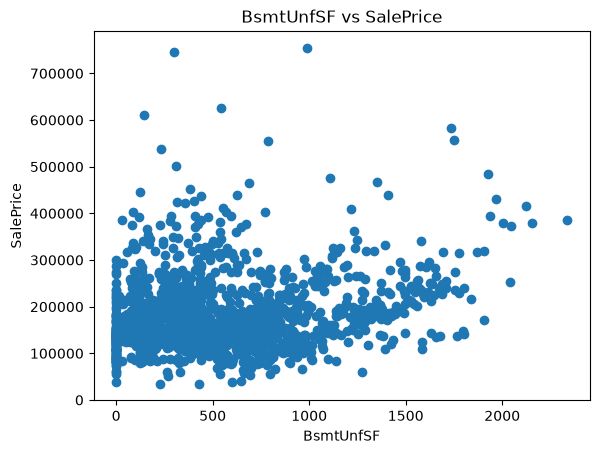

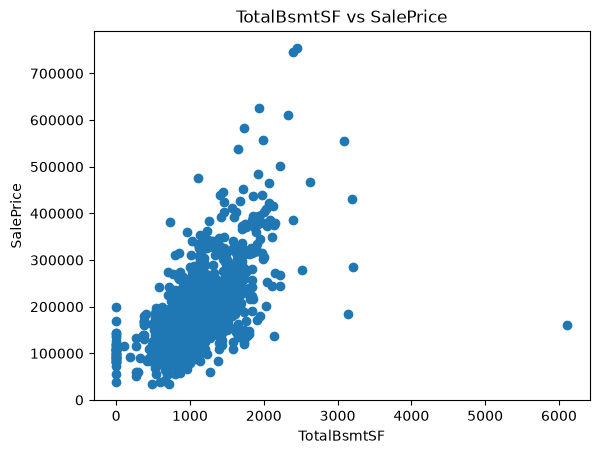

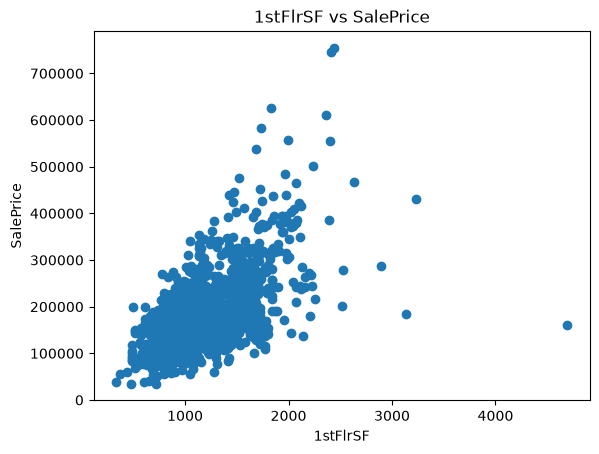

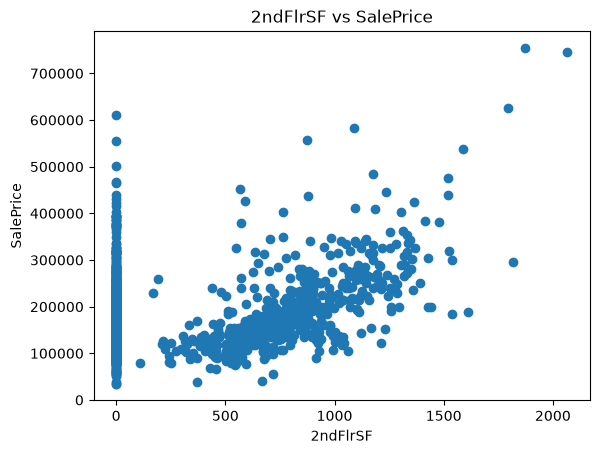

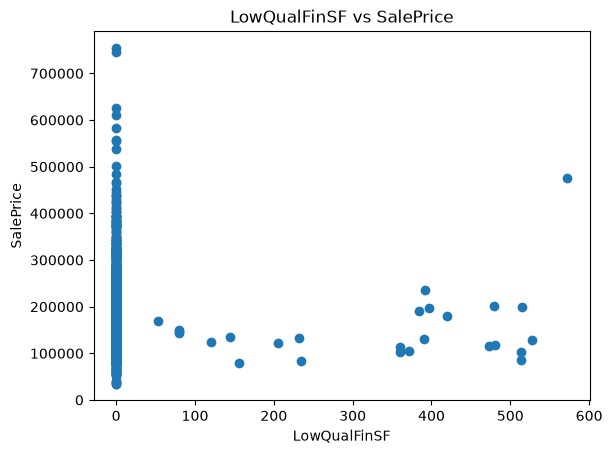

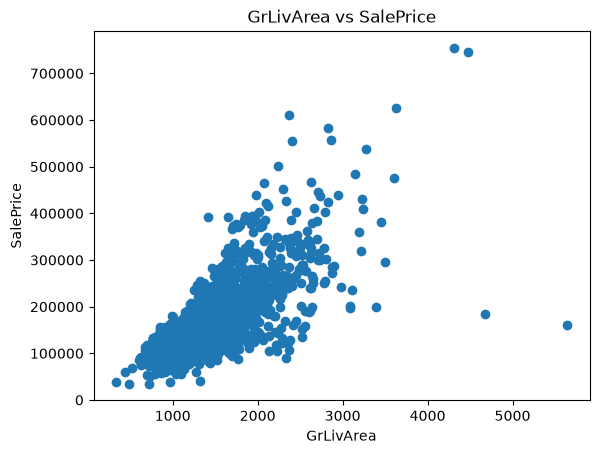

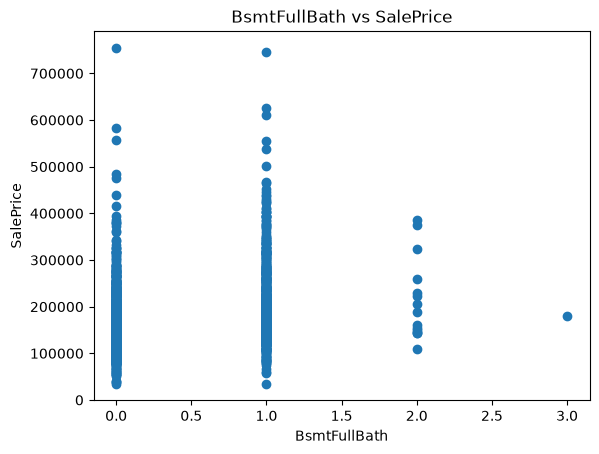

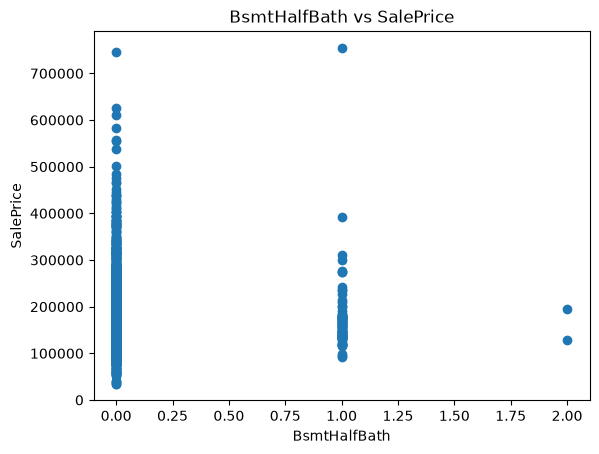

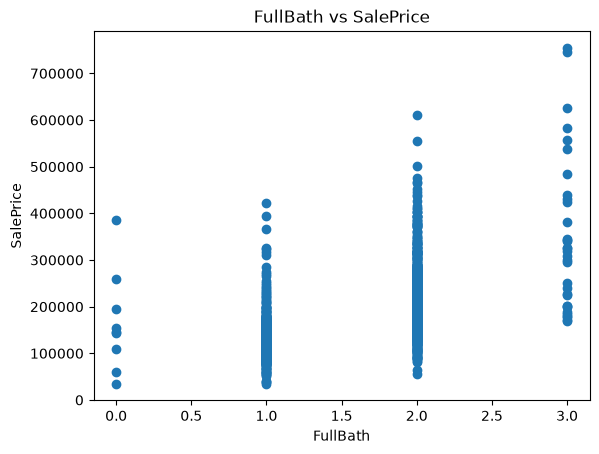

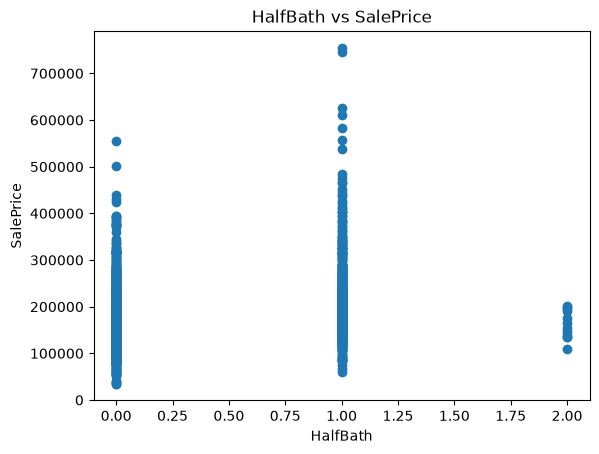

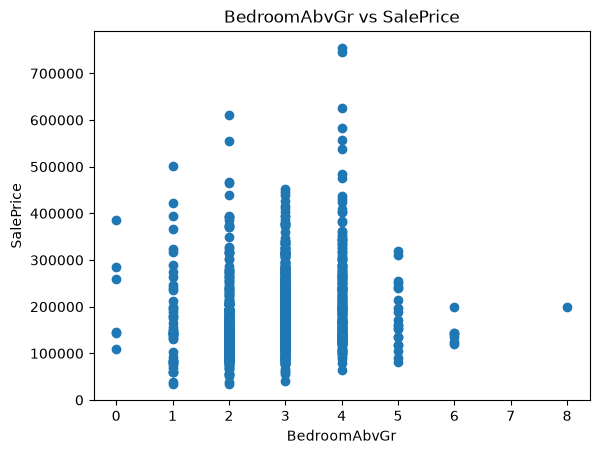

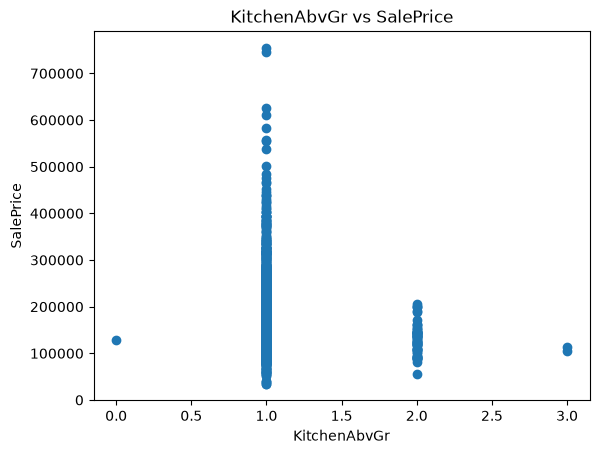

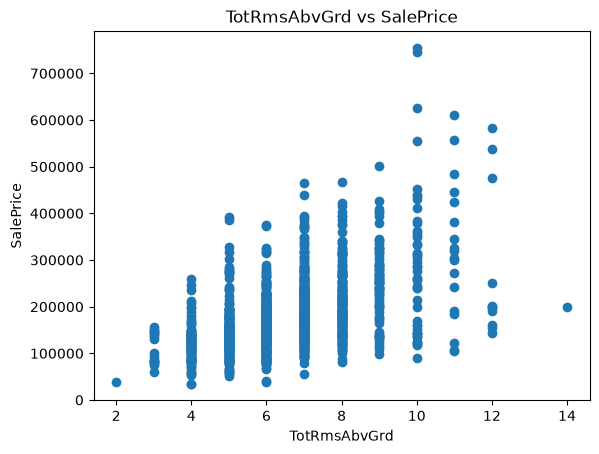

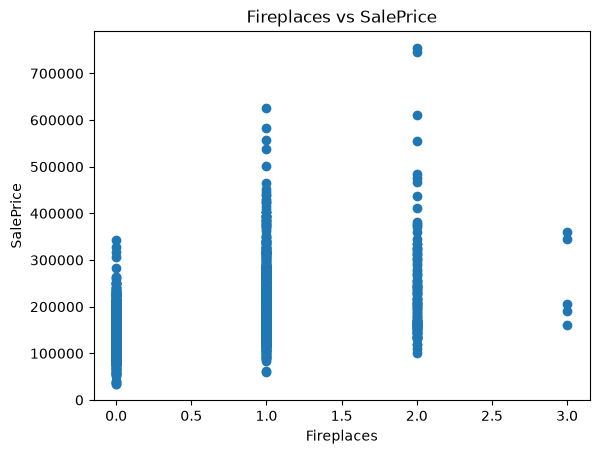

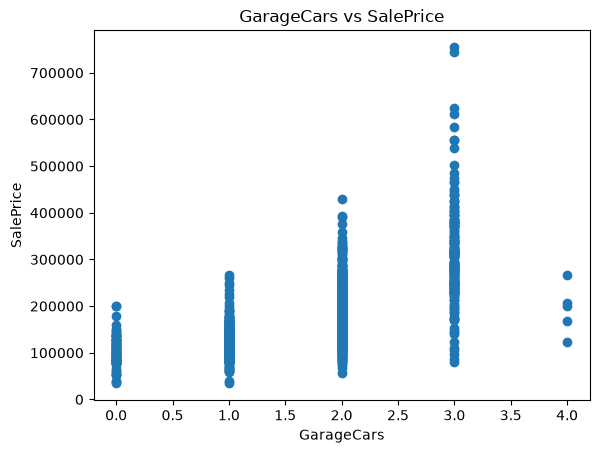

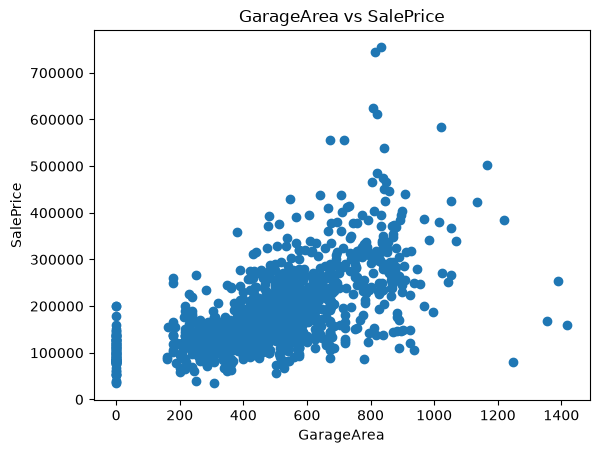

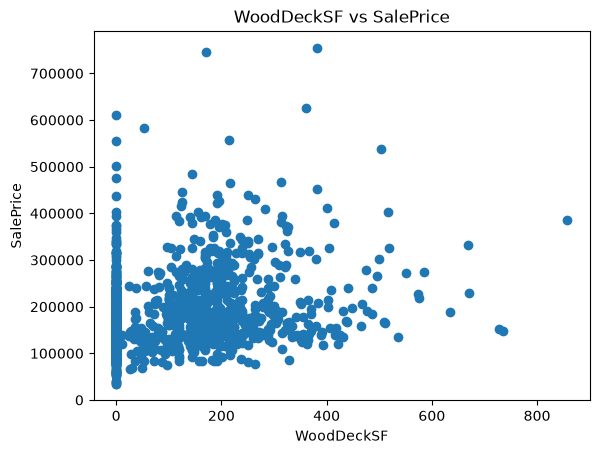

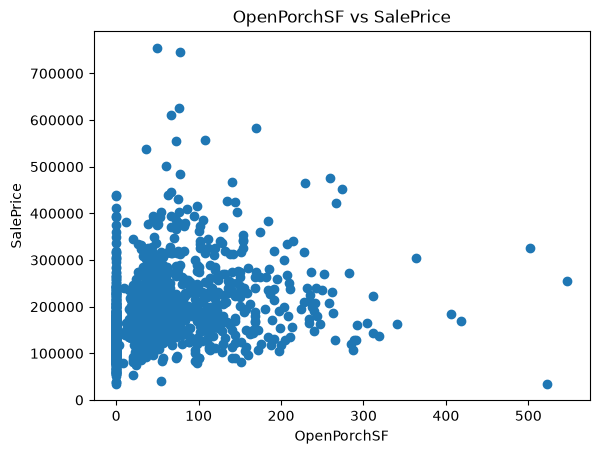

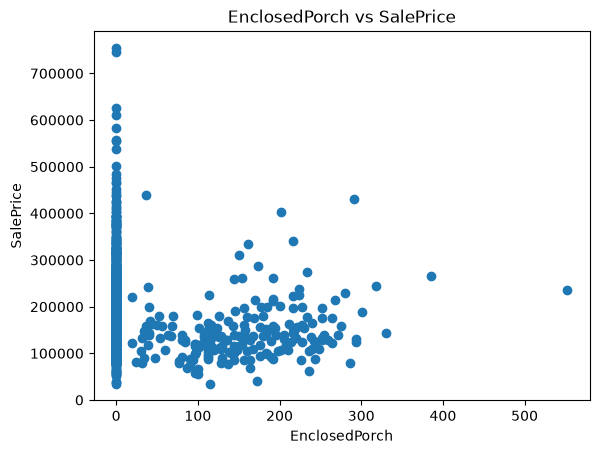

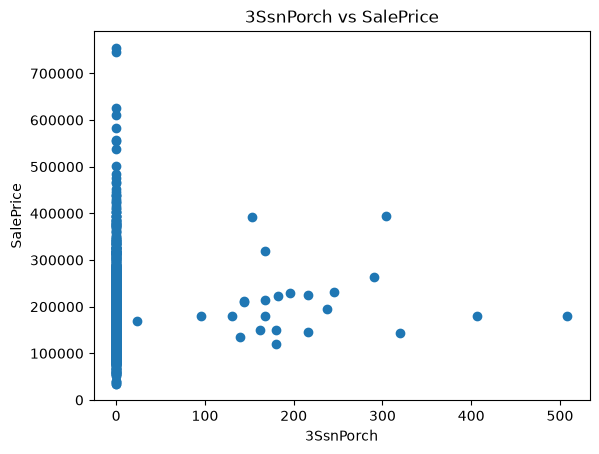

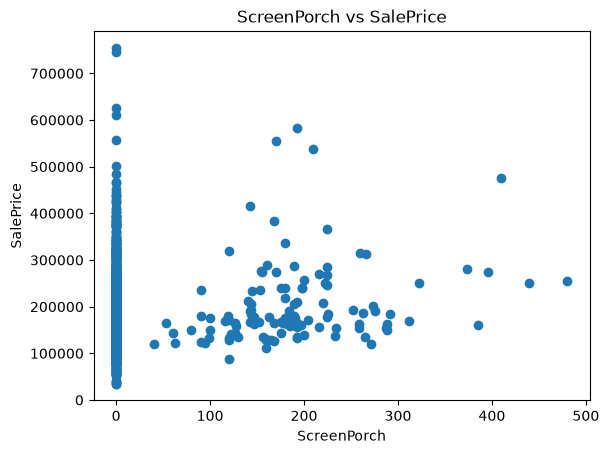

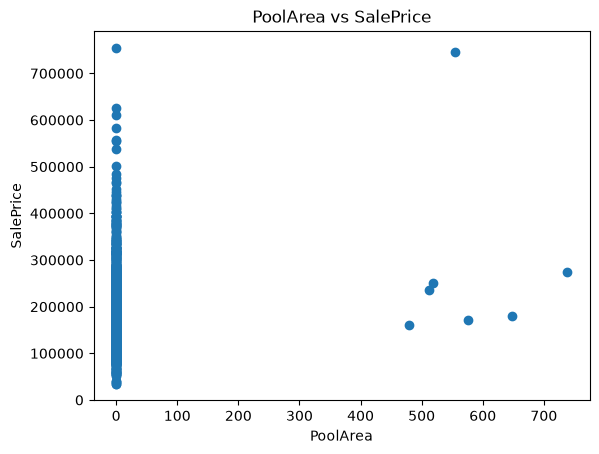

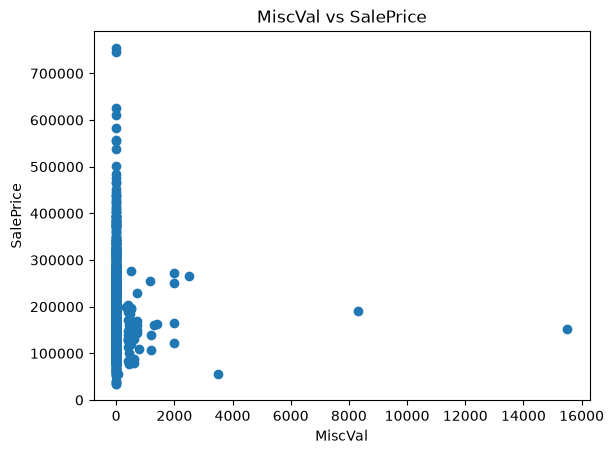

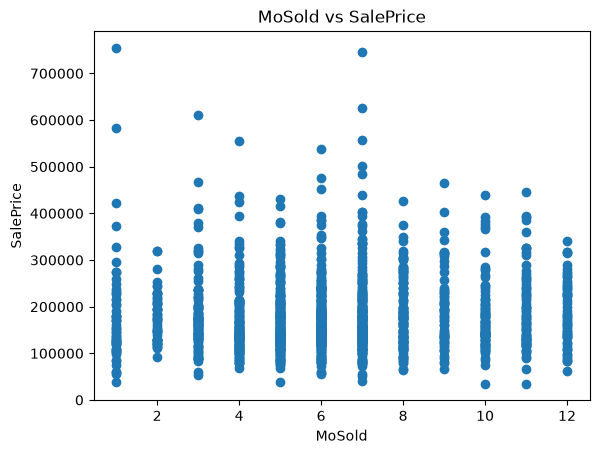

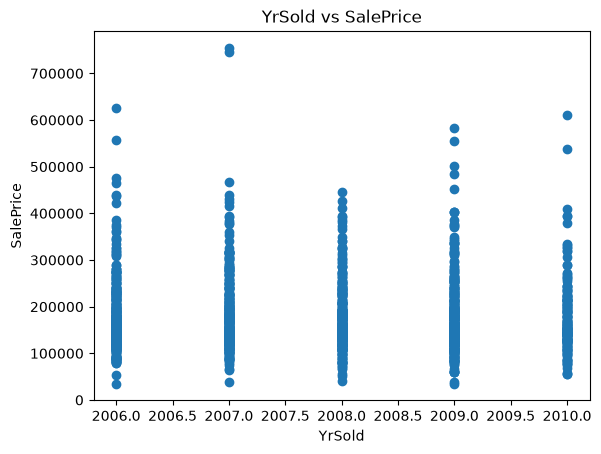

In [39]:
for col in df.columns:

    # Skip SalePrice itself
    if col == "SalePrice":
        continue

    # Skip non-numerical columns
    if df[col].dtype == "str":
        continue

    # Skip columns having null values
    if df[col].isna().any():
        continue

    # Plot
    plt.scatter(df[col], df["SalePrice"])
    plt.xlabel(col)
    plt.ylabel("SalePrice")
    plt.title(f"{col} vs SalePrice")
    plt.show()

In [44]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False).head(20)

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageQual       5.547945
GarageFinish     5.547945
GarageType       5.547945
GarageYrBlt      5.547945
GarageCond       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtCond         2.534247
BsmtQual         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
Condition2       0.000000
dtype: float64

In [42]:
df.isnull().sum().sum()

np.int64(7829)

<Axes: xlabel='SalePrice', ylabel='Count'>

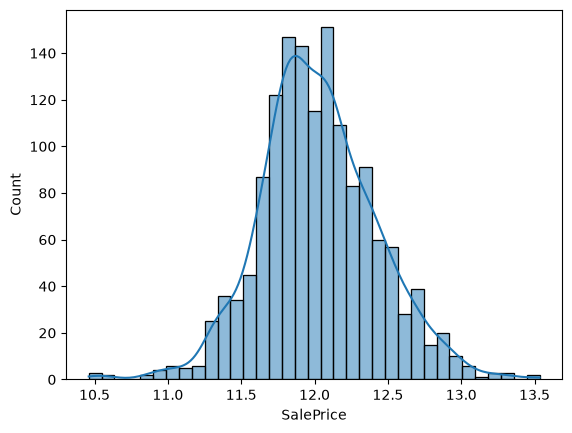

In [59]:
import numpy as np
sns.histplot(np.log1p(df["SalePrice"]), kde=True)

In [60]:
df["SalePrice_log"] = np.log1p(df["SalePrice"])

In [61]:

# -----------------------------
# 1. Categorical columns where NaN means "None / does not exist"
# -----------------------------

none_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "MasVnrType",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

for col in none_cols:
    df[col] = df[col].fillna("None")


# -----------------------------
# 2. Numerical columns where NaN means "does not exist"
# -----------------------------

zero_cols = [
    "GarageYrBlt",
    "MasVnrArea"
]

for col in zero_cols:
    df[col] = df[col].fillna(0)


# -----------------------------
# 3. LotFrontage
#    Use median frontage within each Neighborhood
# -----------------------------

df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)


# -----------------------------
# 4. Electrical
#    Only 1 missing value -> use mode
# -----------------------------

df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

In [64]:
df.isnull().sum().sum()

np.int64(0)

In [66]:
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,SalePrice_log
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,None,None,None,0,2,2008,WD,Normal,208500,12.247699
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,None,None,None,0,5,2007,WD,Normal,181500,12.109016
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,None,None,None,0,9,2008,WD,Normal,223500,12.317171
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,None,None,None,0,2,2006,WD,Abnorml,140000,11.849405
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,None,None,None,0,12,2008,WD,Normal,250000,12.429220
5,6,50,RL,85.0,14115,Pave,None,IR1,Lvl,AllPub,...,None,MnPrv,Shed,700,10,2009,WD,Normal,143000,11.870607
6,7,20,RL,75.0,10084,Pave,None,Reg,Lvl,AllPub,...,None,None,None,0,8,2007,WD,Normal,307000,12.634606
7,8,60,RL,80.0,10382,Pave,None,IR1,Lvl,AllPub,...,None,None,Shed,350,11,2009,WD,Normal,200000,12.206078
8,9,50,RM,51.0,6120,Pave,None,Reg,Lvl,AllPub,...,None,None,None,0,4,2008,WD,Abnorml,129900,11.774528
9,10,190,RL,50.0,7420,Pave,None,Reg,Lvl,AllPub,...,None,None,None,0,1,2008,WD,Normal,118000,11.678448


In [74]:
numeric_cols = df.select_dtypes(include=np.number).columns

skewness = df[numeric_cols].skew().sort_values(ascending=False)

print(skewness)

MiscVal          24.476794
PoolArea         14.828374
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
SalePrice         1.882876
TotalBsmtSF       1.524255
MSSubClass        1.407657
BsmtUnfSF         0.920268
2ndFlrSF          0.813030
OverallCond       0.693067
TotRmsAbvGrd      0.676341
HalfBath          0.675897
Fireplaces        0.649565
BsmtFullBath      0.596067
MasVnrArea        0.503532
OverallQual       0.216944
MoSold            0.212053
BedroomAbvGr      0.211790
GarageArea        0.179981
WoodDeckSF        0.153537
SalePrice_log     0.121347
YrSold            0.096269
1stFlrSF          0.080114
FullBath          0.036562
Id                0.000000
GrLivArea        -0.006140
OpenPorchSF      -0.023397
LotArea          -0.137404
GarageCars       -0.342549
YearRemodAdd     -0.503562
YearBuilt        -0.613461
BsmtFinSF1       -0.618410
L

In [73]:
corr = df.select_dtypes(include=np.number).corr()["SalePrice_log"].sort_values(
    ascending=False
)

print(corr)

SalePrice_log    1.000000
SalePrice        0.948374
OverallQual      0.817185
GrLivArea        0.730254
GarageCars       0.680625
GarageArea       0.650888
TotalBsmtSF      0.612134
1stFlrSF         0.608955
FullBath         0.594771
YearBuilt        0.586570
YearRemodAdd     0.565608
TotRmsAbvGrd     0.534422
Fireplaces       0.489450
OpenPorchSF      0.459948
MasVnrArea       0.413318
LotArea          0.399923
LotFrontage      0.361816
GarageYrBlt      0.349013
WoodDeckSF       0.343039
2ndFlrSF         0.319300
HalfBath         0.313982
BsmtFullBath     0.236224
BsmtUnfSF        0.221985
BedroomAbvGr     0.209043
BsmtFinSF1       0.208099
ScreenPorch      0.121208
PoolArea         0.069798
MoSold           0.057330
3SsnPorch        0.054900
BsmtFinSF2       0.004832
BsmtHalfBath    -0.005149
Id              -0.017942
MiscVal         -0.020021
OverallCond     -0.036868
YrSold          -0.037263
LowQualFinSF    -0.037963
MSSubClass      -0.073959
KitchenAbvGr    -0.147548
EnclosedPorc

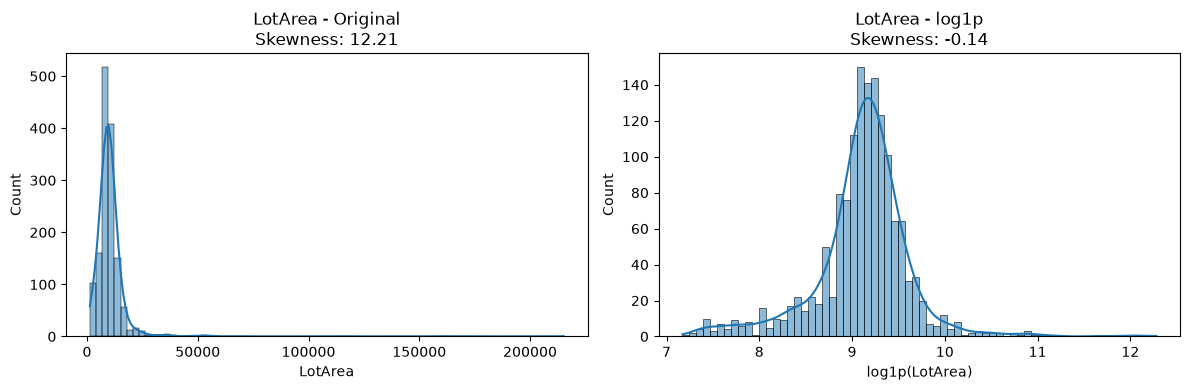

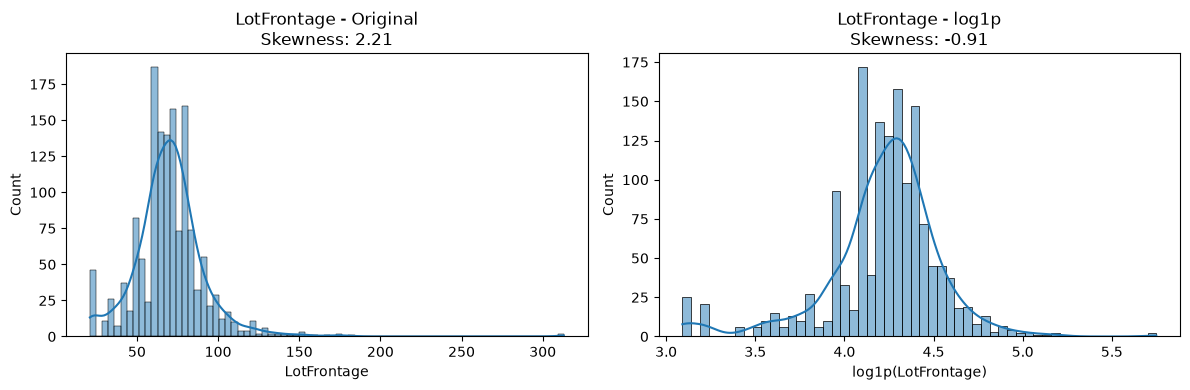

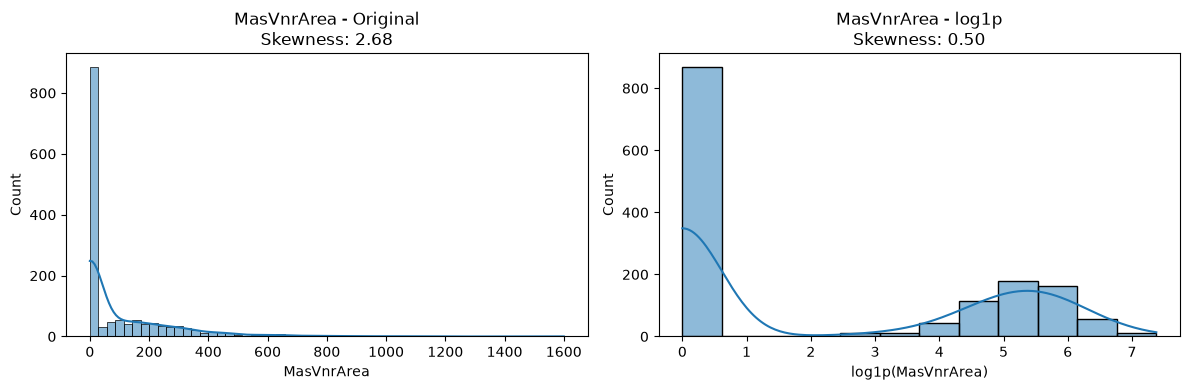

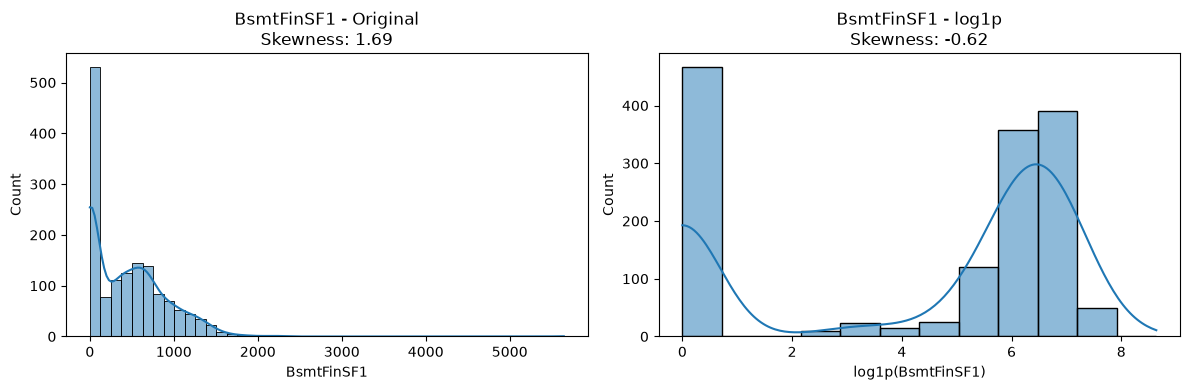

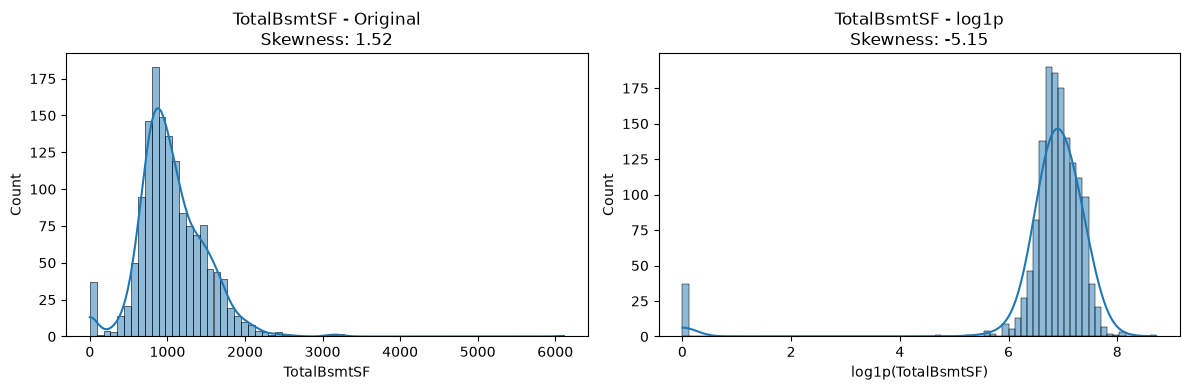

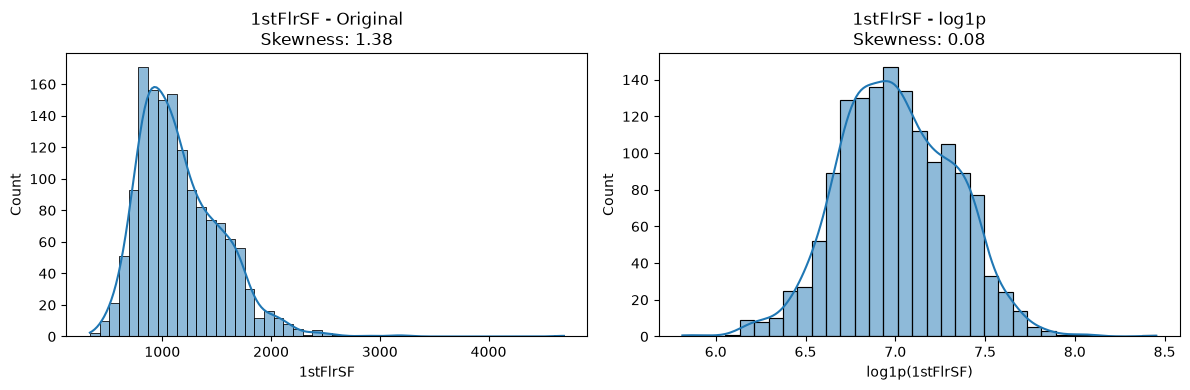

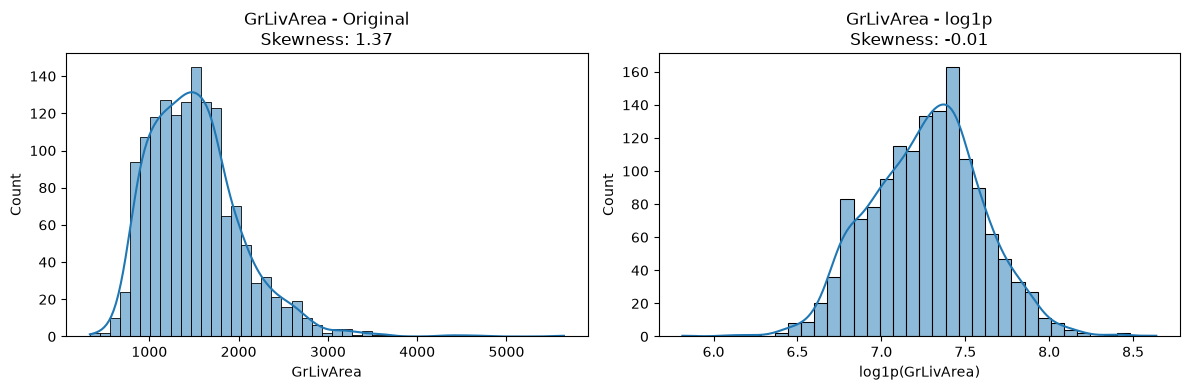

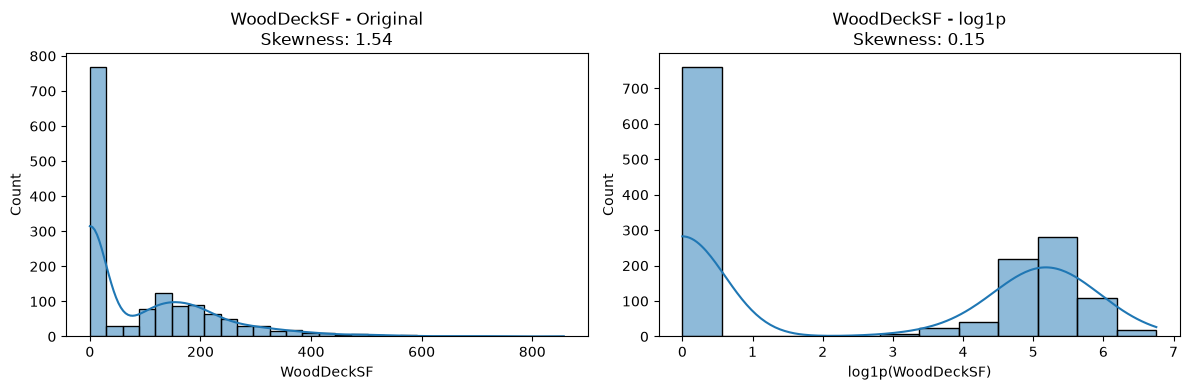

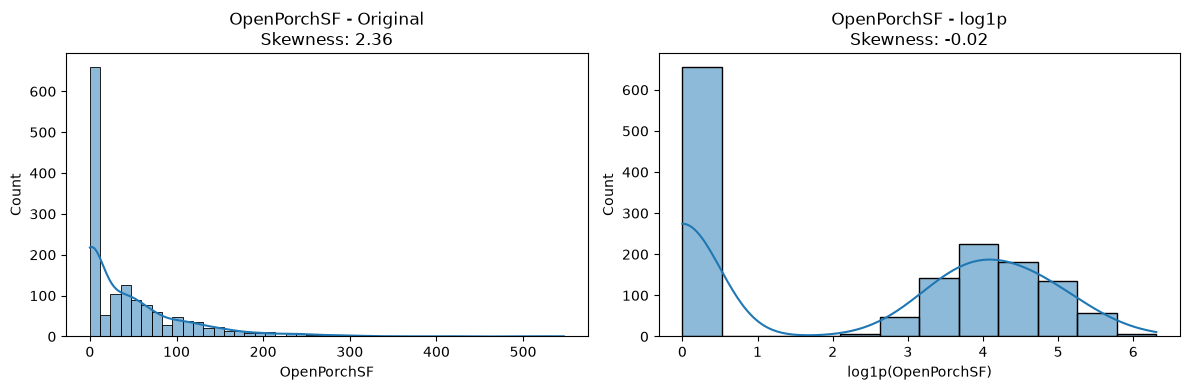

In [69]:
cols_to_check = [
    "LotArea",
    "LotFrontage",
    "MasVnrArea",
    "BsmtFinSF1",
    "TotalBsmtSF",
    "1stFlrSF",
    "GrLivArea",
    "WoodDeckSF",
    "OpenPorchSF"
]

for col in cols_to_check:

    # Original skewness
    original_skew = df[col].skew()

    # Log transformed values
    log_values = np.log1p(df[col])
    log_skew = log_values.skew()

    # Plot original
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    sns.histplot(df[col], kde=True)
    plt.title(f"{col} - Original\nSkewness: {original_skew:.2f}")
    plt.xlabel(col)

    # Plot log transformed
    plt.subplot(1, 2, 2)
    sns.histplot(log_values, kde=True)
    plt.title(f"{col} - log1p\nSkewness: {log_skew:.2f}")
    plt.xlabel(f"log1p({col})")

    plt.tight_layout()
    plt.show()

In [70]:

for col in cols_to_check:
    original = df[col].skew()
    log1p = np.log1p(df[col]).skew()

    print(f"{col:15} Before: {original:.3f}   After: {log1p:.3f}")

LotArea         Before: 12.208   After: -0.137
LotFrontage     Before: 2.213   After: -0.909
MasVnrArea      Before: 2.678   After: 0.504
BsmtFinSF1      Before: 1.686   After: -0.618
TotalBsmtSF     Before: 1.524   After: -5.155
1stFlrSF        Before: 1.377   After: 0.080
GrLivArea       Before: 1.367   After: -0.006
WoodDeckSF      Before: 1.541   After: 0.154
OpenPorchSF     Before: 2.364   After: -0.023


In [71]:
df["TotalBsmtSF"].describe()

count    1460.000000
mean     1057.429452
std       438.705324
min         0.000000
25%       795.750000
50%       991.500000
75%      1298.250000
max      6110.000000
Name: TotalBsmtSF, dtype: float64

In [72]:
log_cols = [
    "LotArea",
    "LotFrontage",
    "MasVnrArea",
    "BsmtFinSF1",
    "1stFlrSF",
    "GrLivArea",
    "WoodDeckSF",
    "OpenPorchSF"
]
for col in log_cols:
    df[col] = np.log1p(df[col])

In [75]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


MSZoning
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

Street
Street
Pave    1454
Grvl       6
Name: count, dtype: int64

Alley
Alley
None    1369
Grvl      50
Pave      41
Name: count, dtype: int64

LotShape
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

LandContour
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64

Utilities
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

LotConfig
LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

LandSlope
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64

Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
Name: count, dtype: int64

Condition1
Condition1
Norm      1260
Feedr       81

C:\Users\hp\AppData\Local\Temp\ipykernel_19448\678327619.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


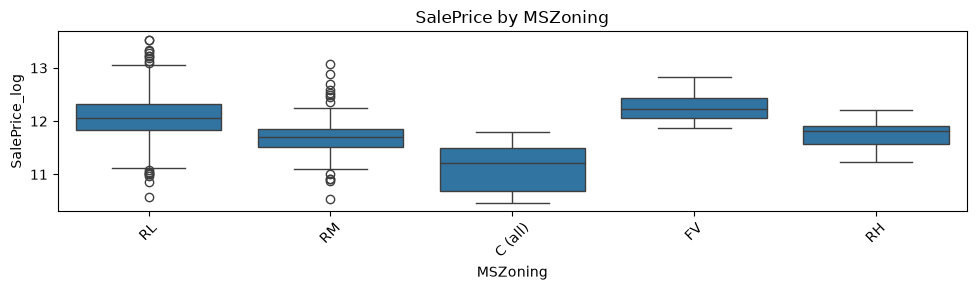

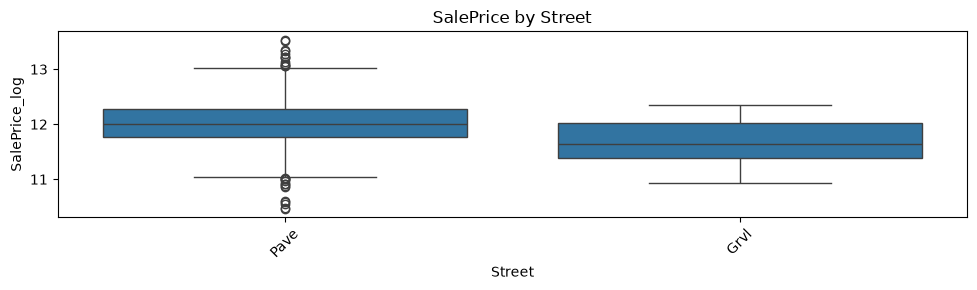

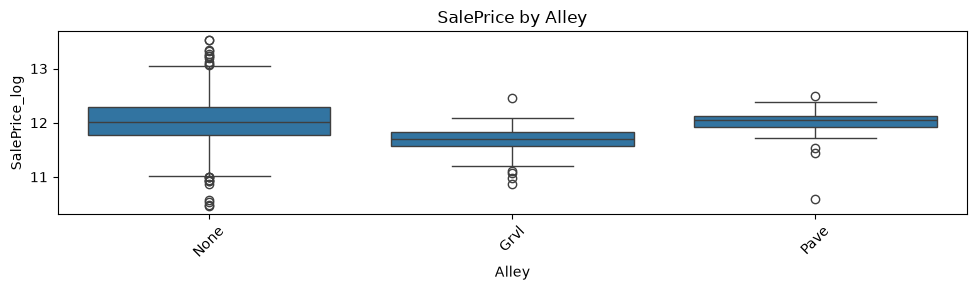

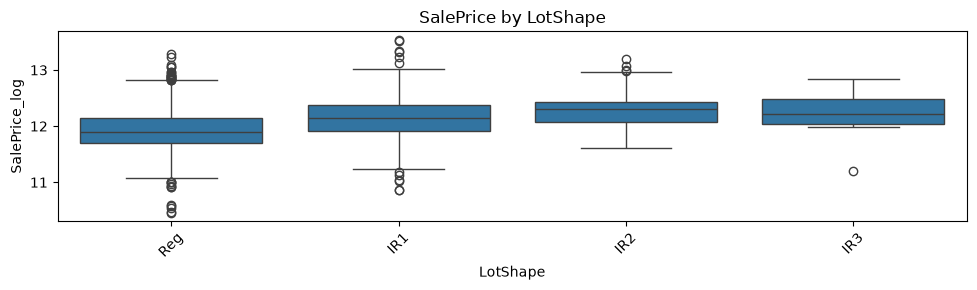

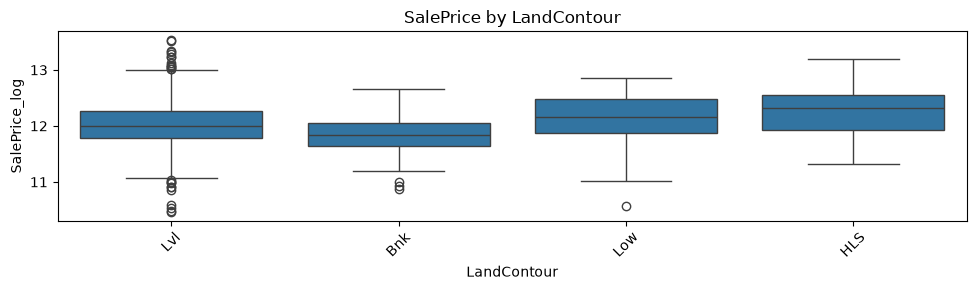

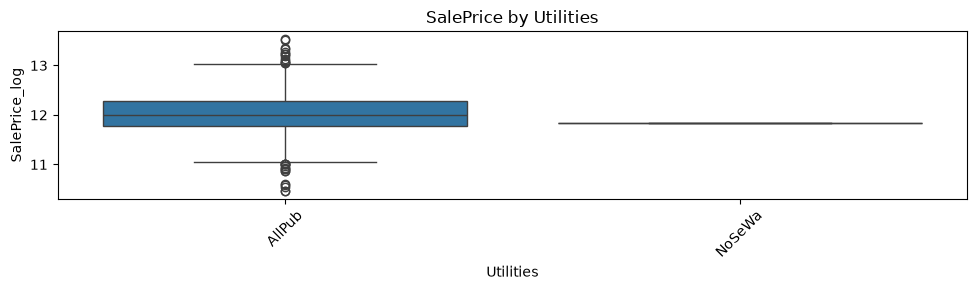

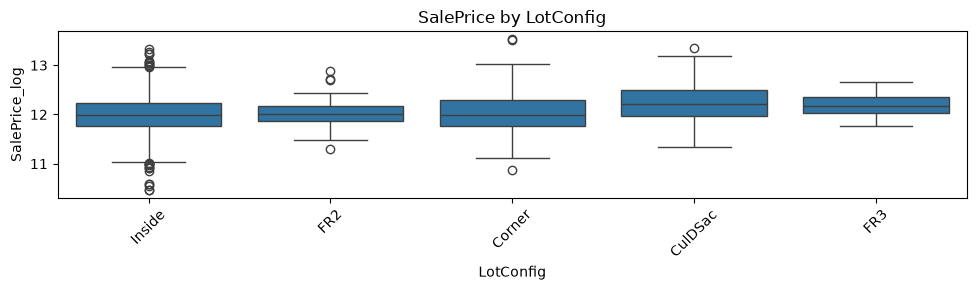

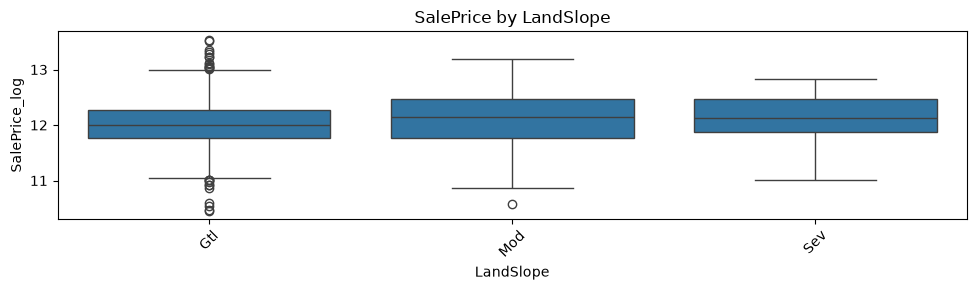

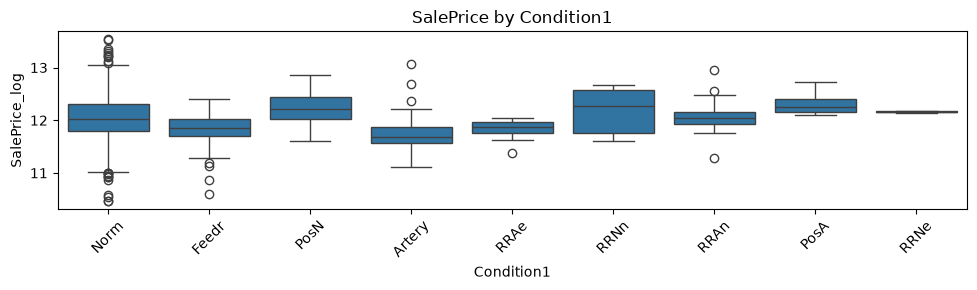

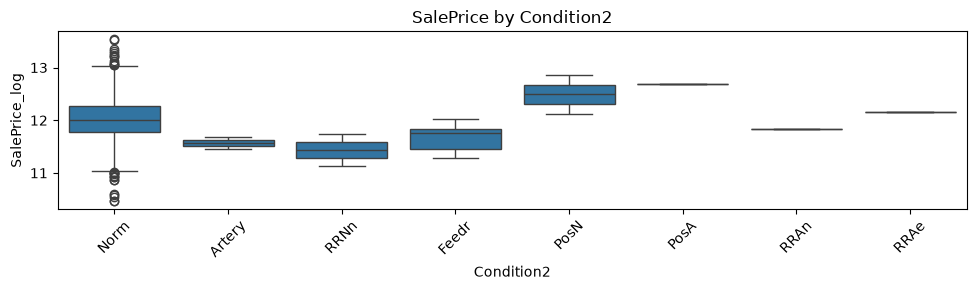

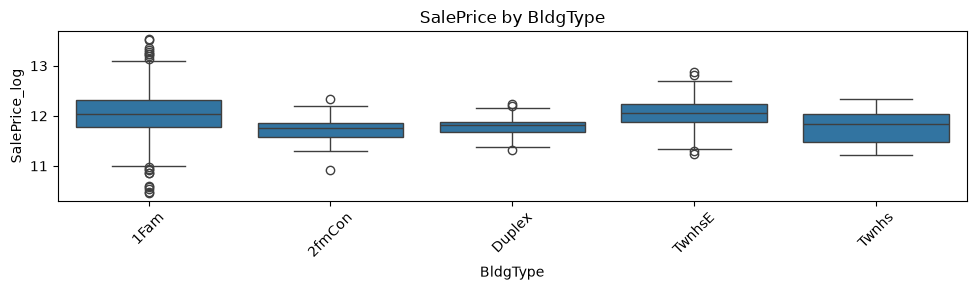

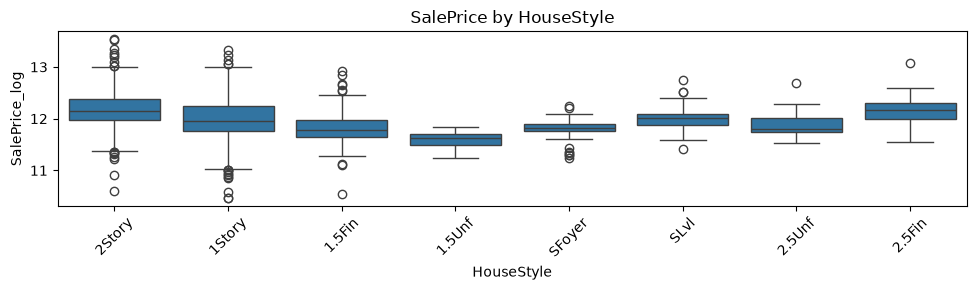

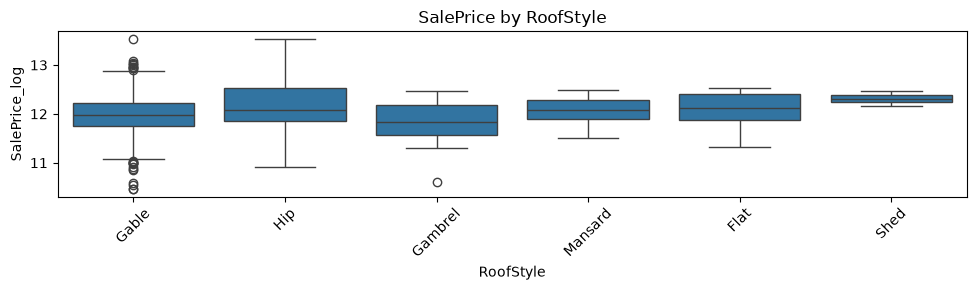

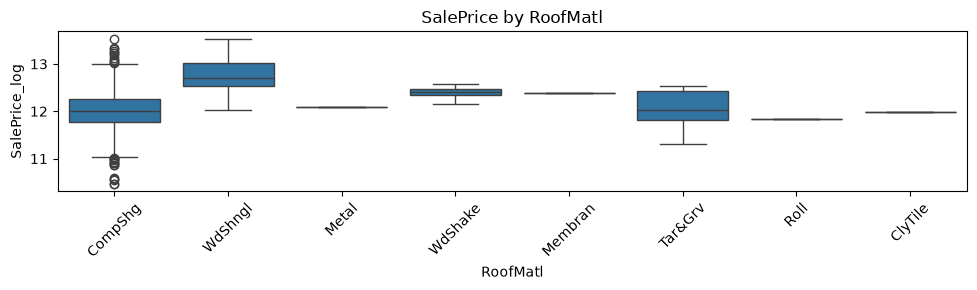

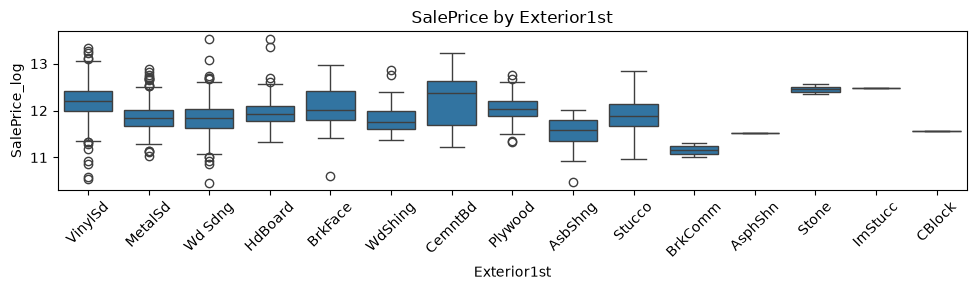

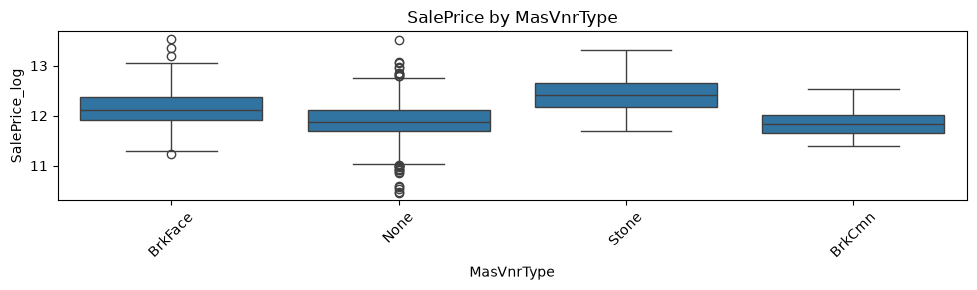

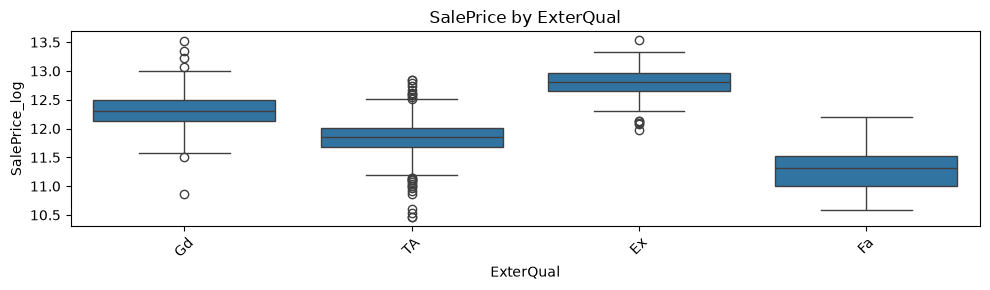

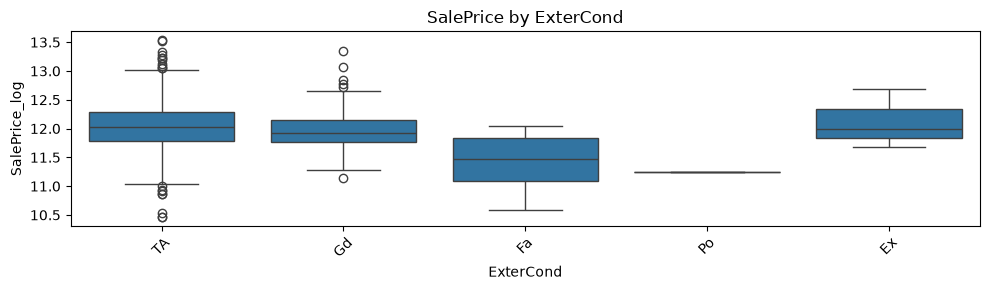

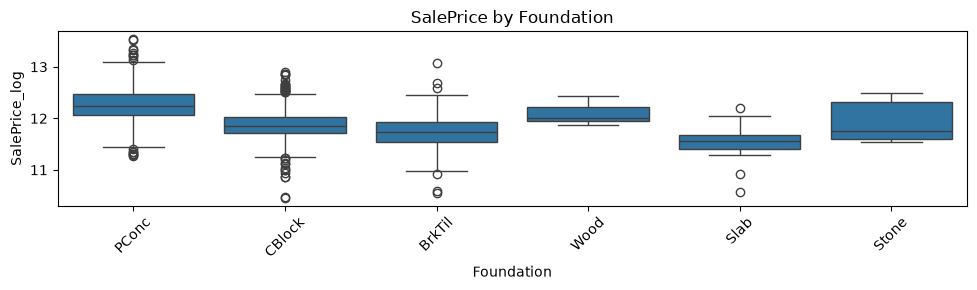

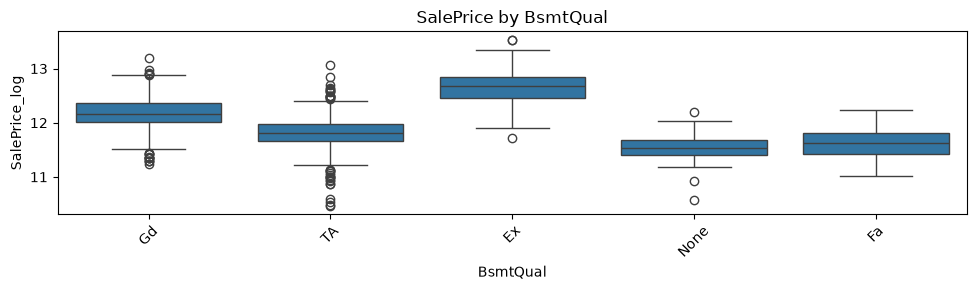

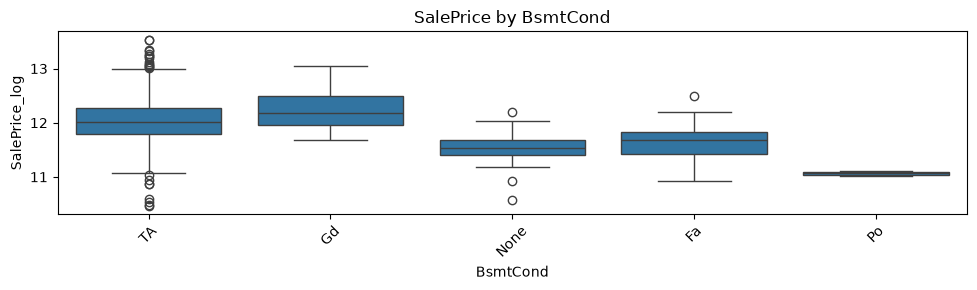

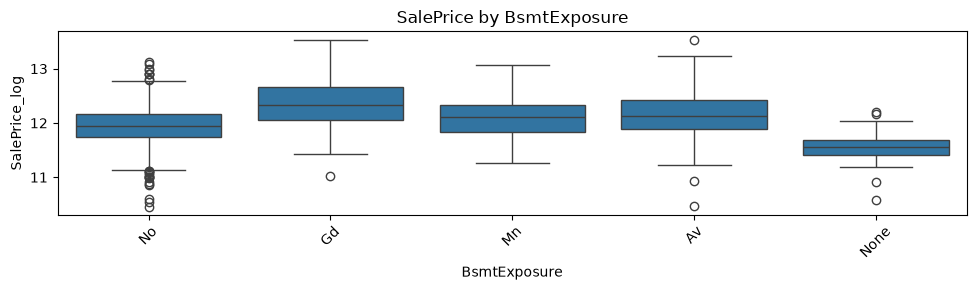

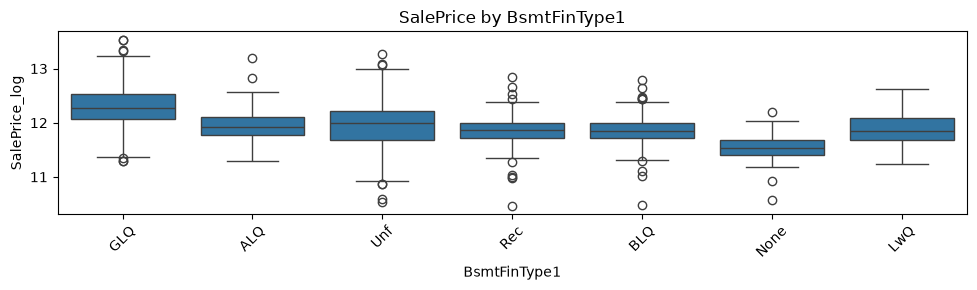

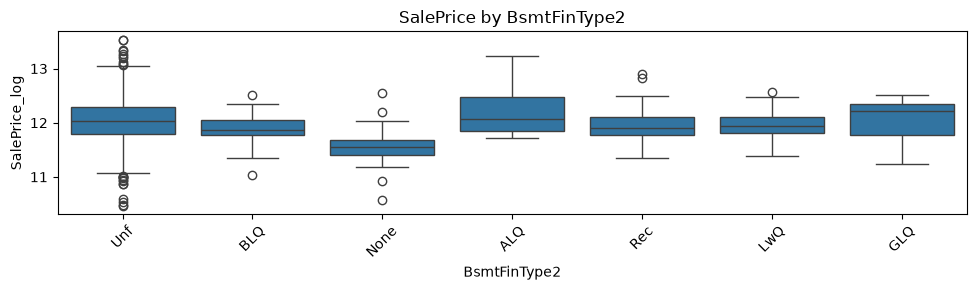

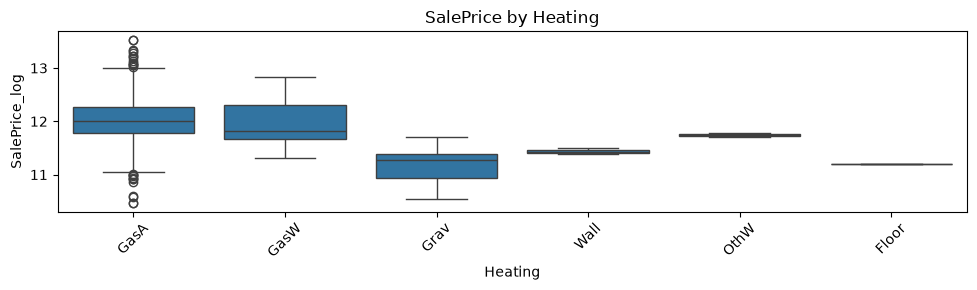

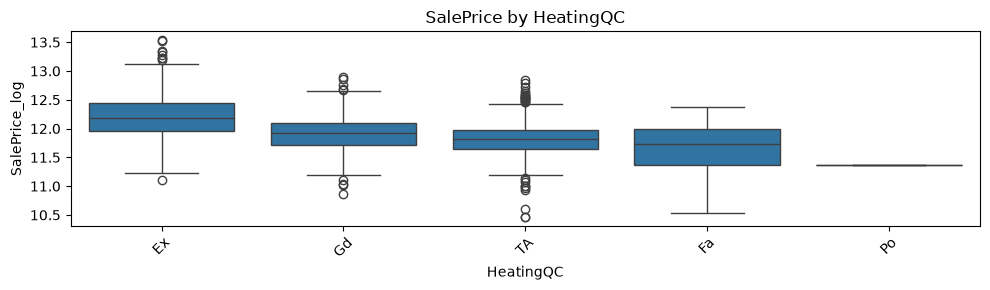

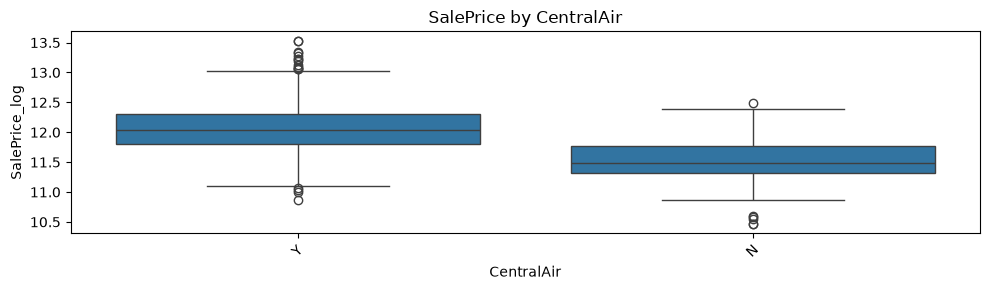

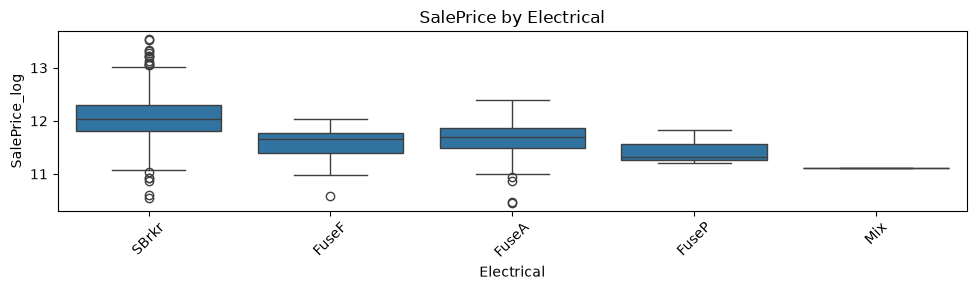

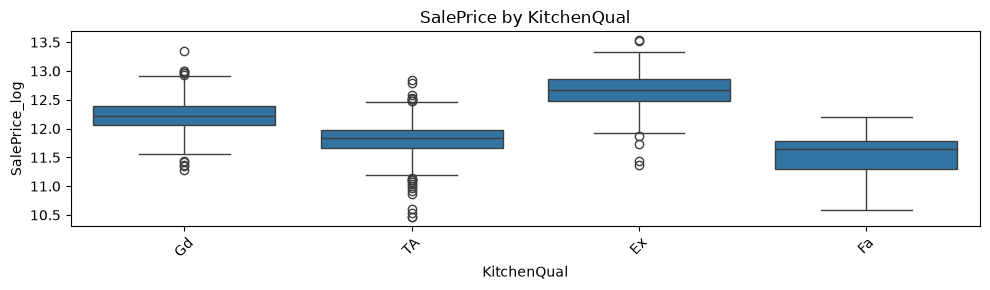

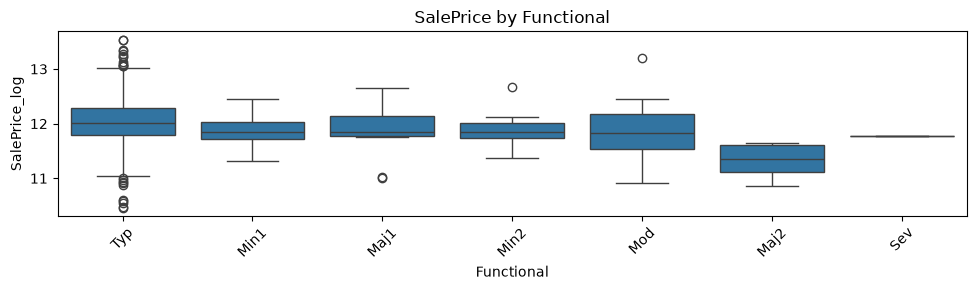

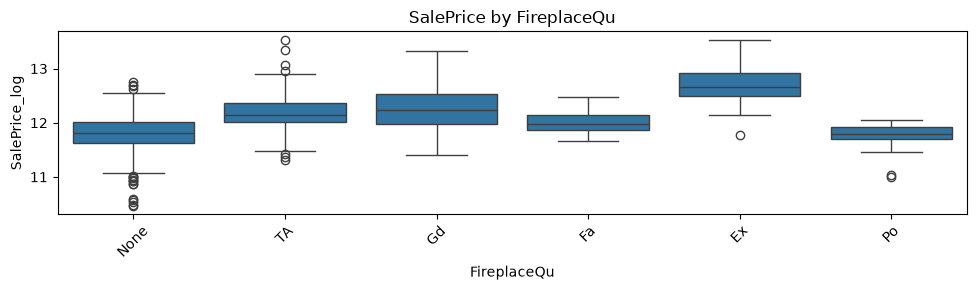

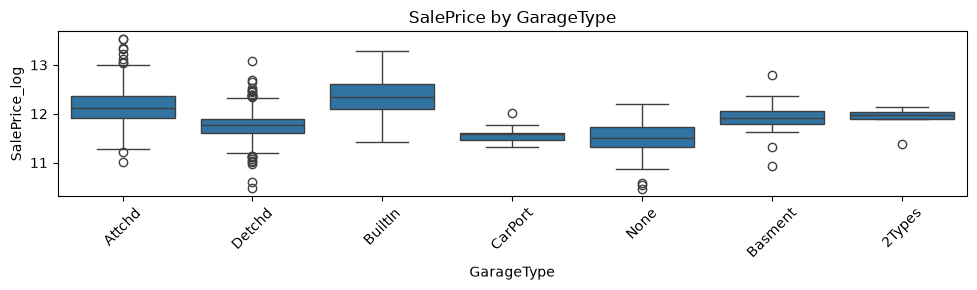

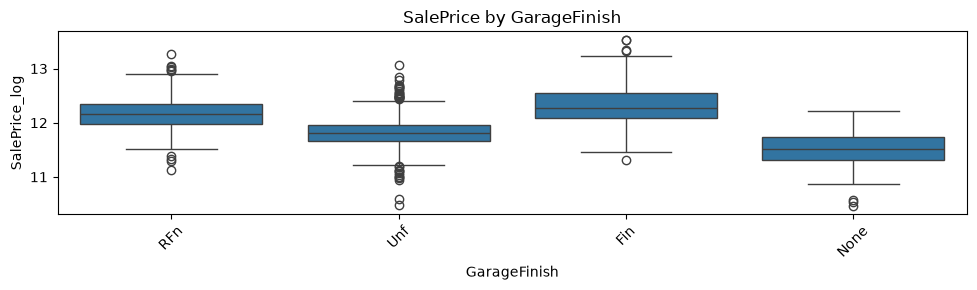

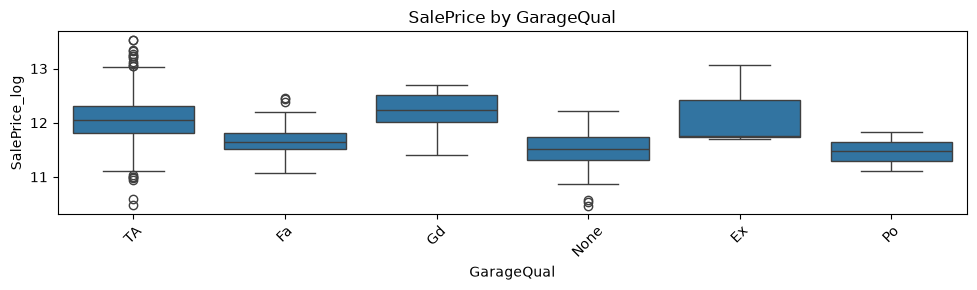

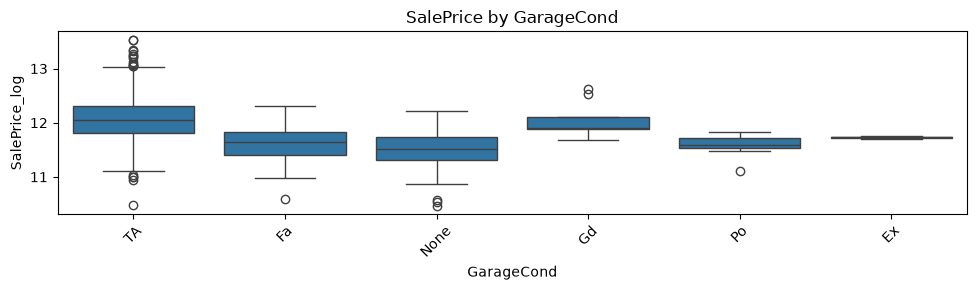

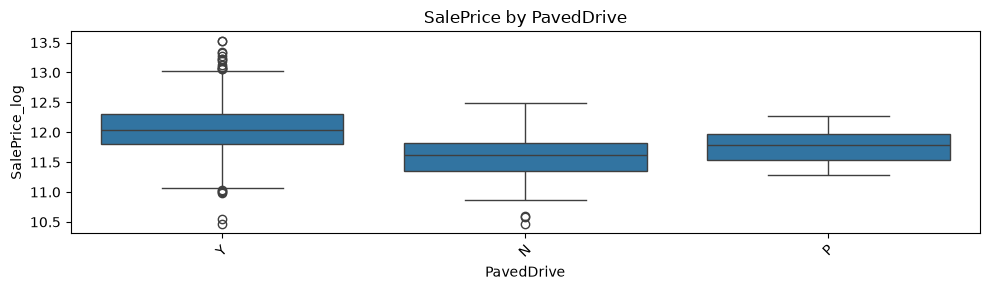

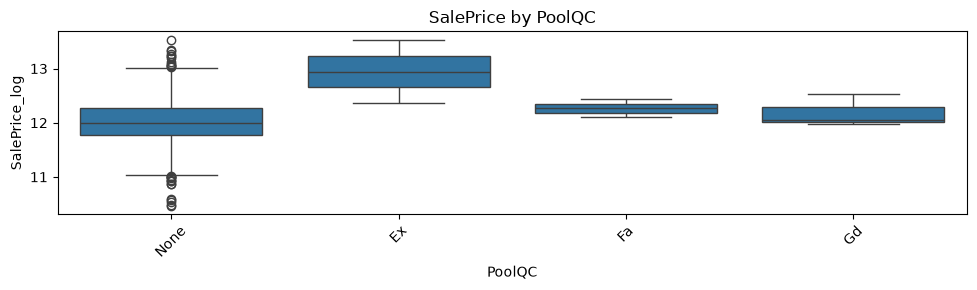

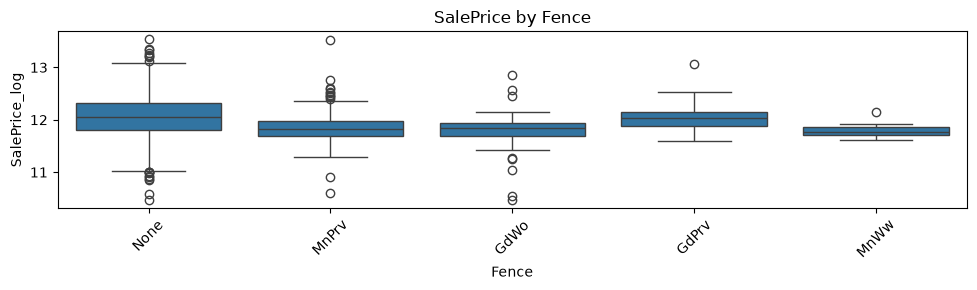

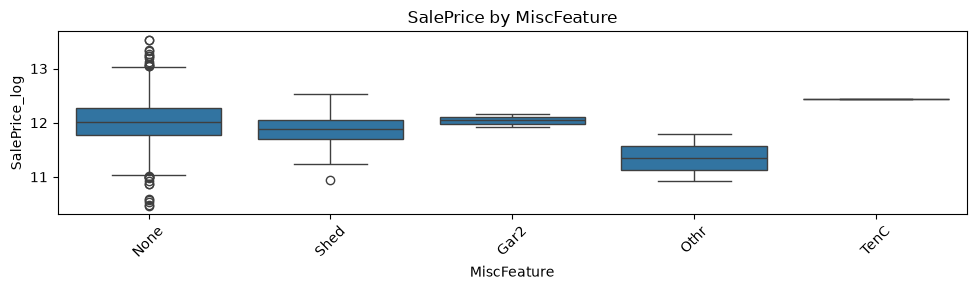

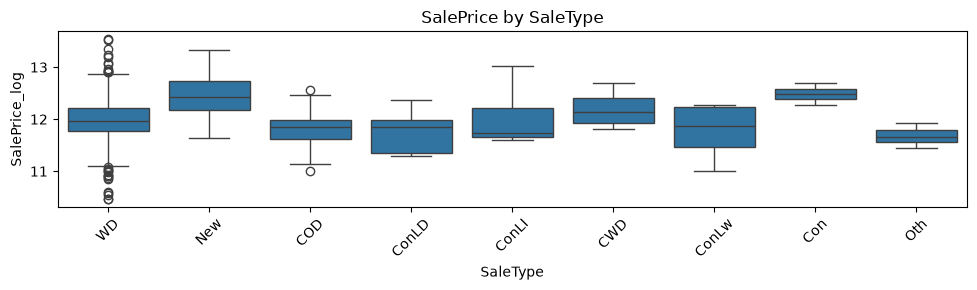

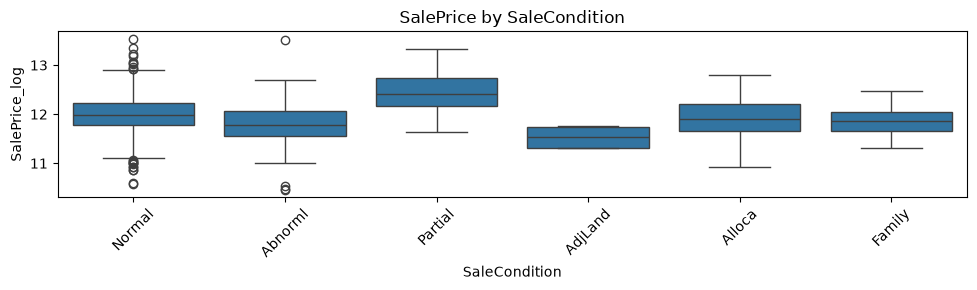

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

cat_cols = df.select_dtypes(include="str").columns

for col in cat_cols:
    if df[col].nunique() <= 15:
        plt.figure(figsize=(10, 3))
        sns.boxplot(data=df, x=col, y="SalePrice_log")
        plt.title(f"SalePrice by {col}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

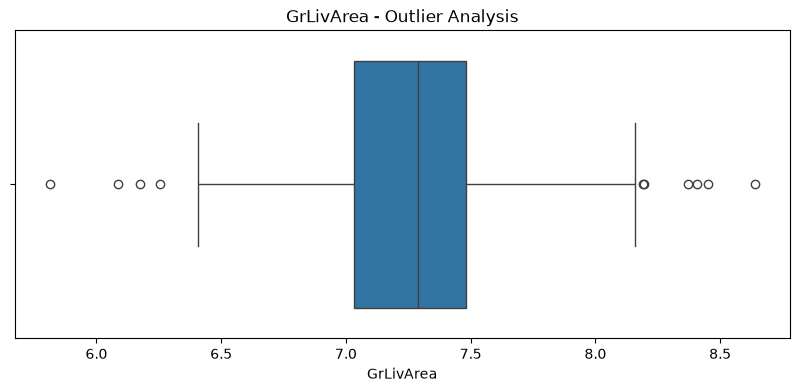

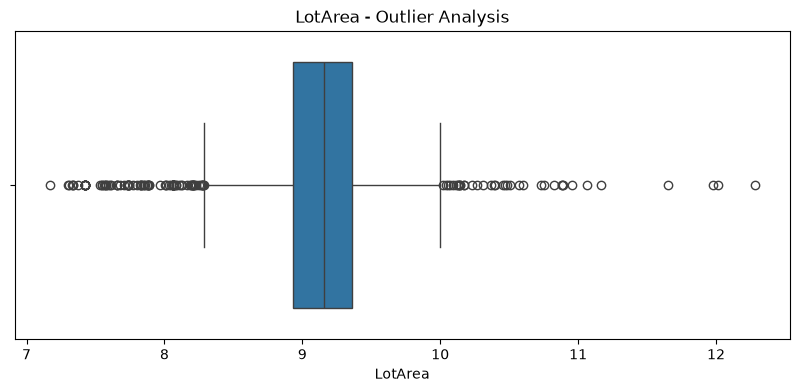

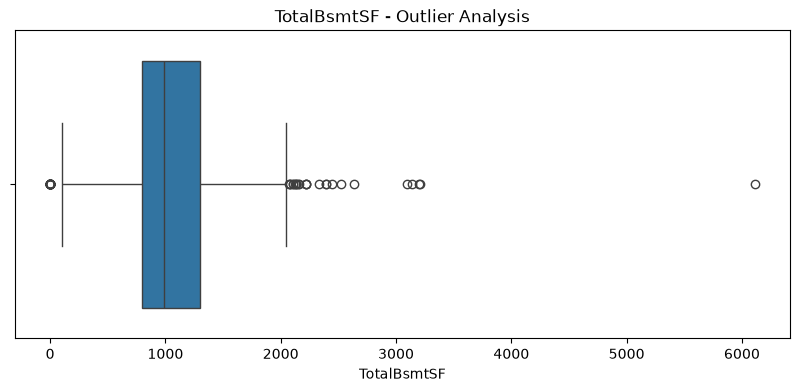

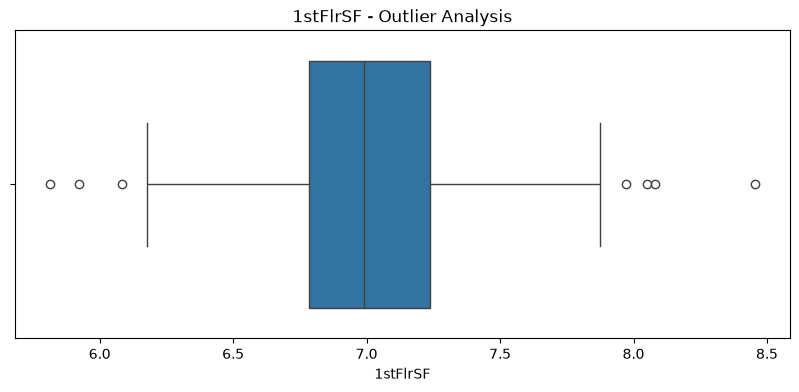

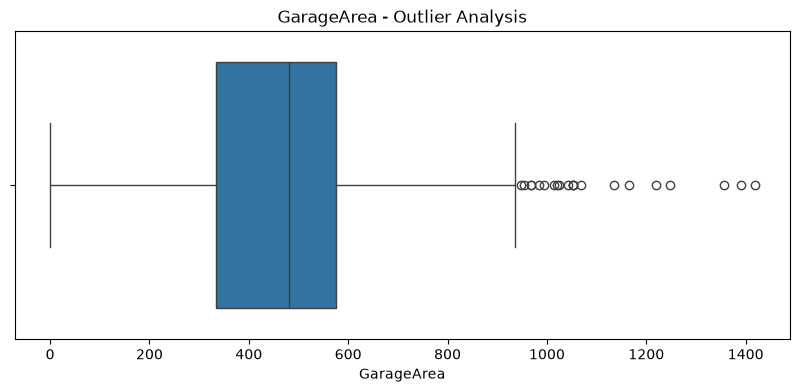

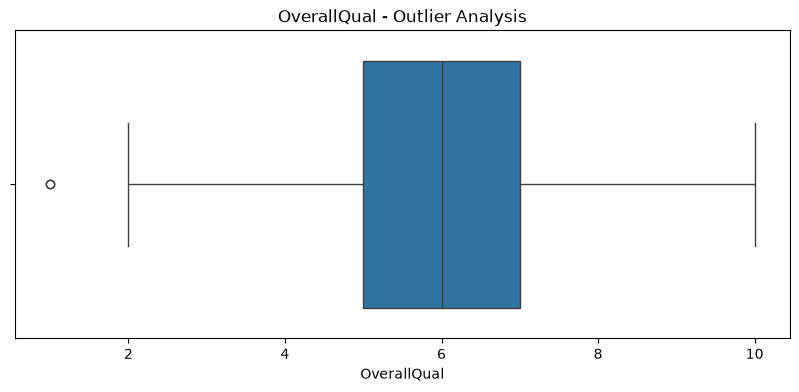

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

outlier_cols = [
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "GarageArea",
    "OverallQual"
]

for col in outlier_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"{col} - Outlier Analysis")
    plt.show()

In [84]:
df[df["GrLivArea"] > 8.3][
    ["GrLivArea", "OverallQual", "YearBuilt",
     "GarageCars", "TotalBsmtSF", "SalePrice", "SalePrice_log"]
]

,GrLivArea,OverallQual,YearBuilt,GarageCars,TotalBsmtSF,SalePrice,SalePrice_log
691,8.370316,10,1994,3,2444,755000,13.534474
1182,8.406708,10,1996,3,2396,745000,13.521141


In [83]:
df = df.drop(index=[523, 1298])

In [85]:
outlier_cols = [
    "LotArea",
    "GrLivArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "GarageArea",
    "MasVnrArea",
    "BsmtFinSF1",
    "WoodDeckSF",
    "OpenPorchSF"
]

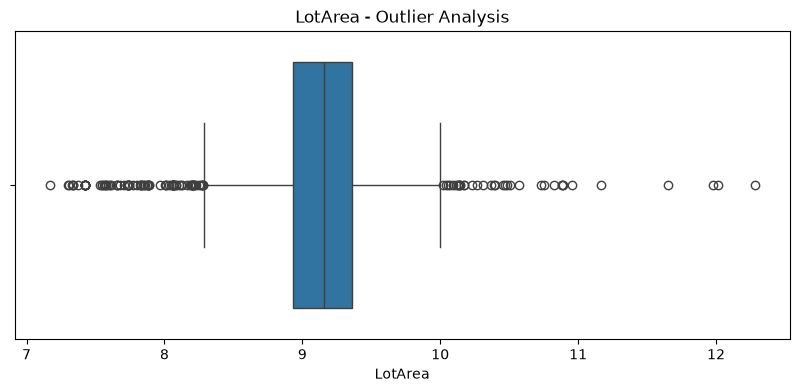

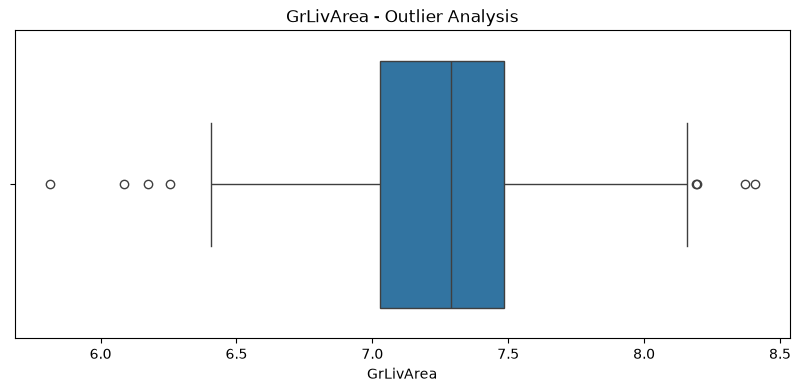

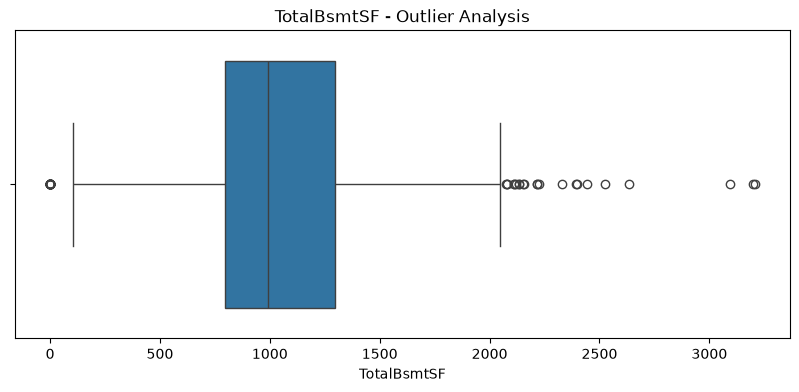

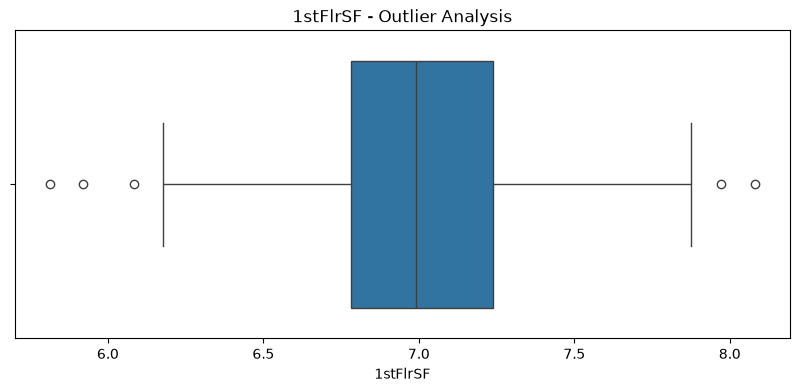

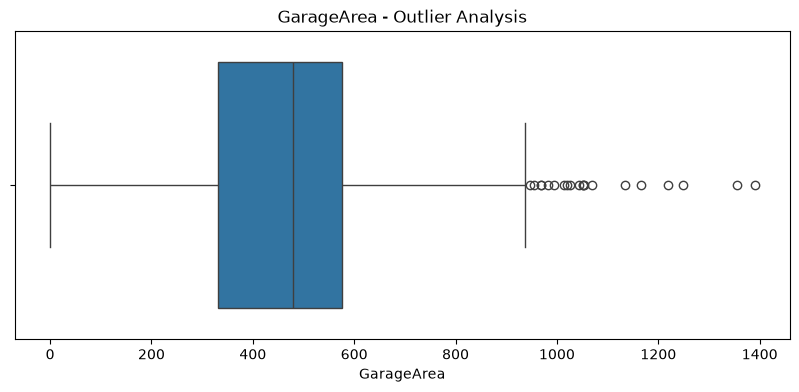

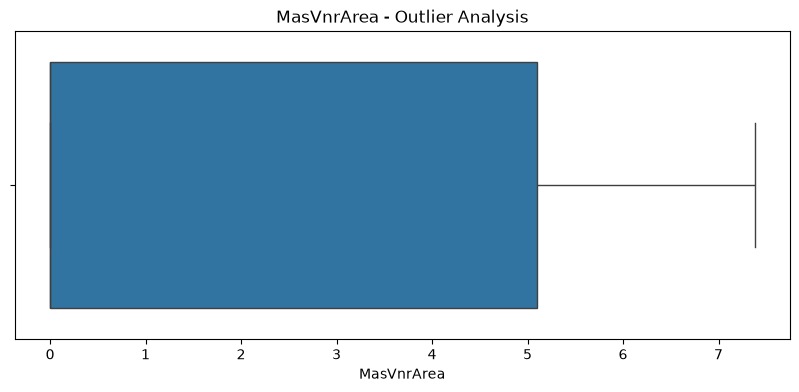

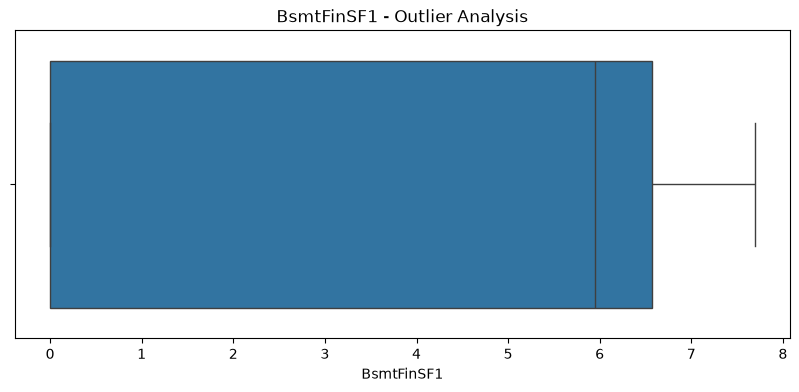

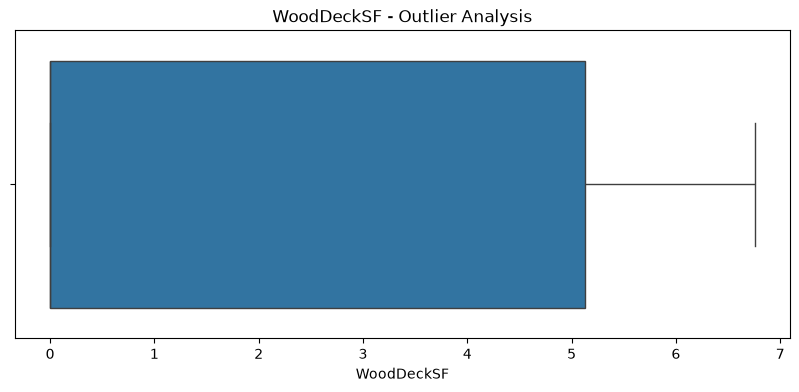

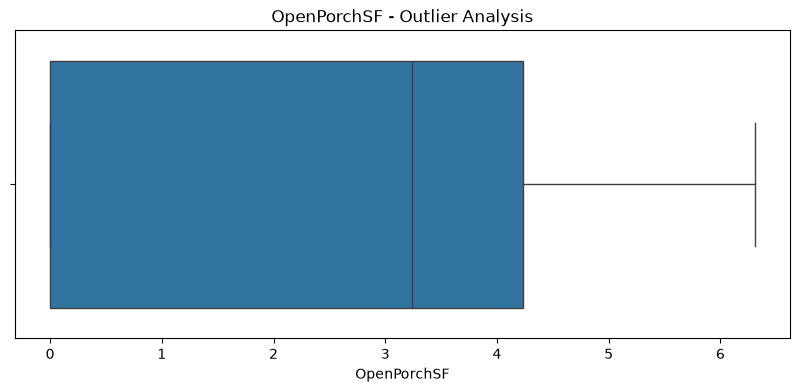

In [86]:
for col in outlier_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"{col} - Outlier Analysis")
    plt.show()

In [87]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col}")
    print(f"Lower: {lower:.2f}")
    print(f"Upper: {upper:.2f}")
    print(f"Outliers: {len(outliers)}")


LotArea
Lower: 8.28
Upper: 10.00
Outliers: 129

GrLivArea
Lower: 6.35
Upper: 8.16
Outliers: 8

TotalBsmtSF
Lower: 43.00
Upper: 2049.00
Outliers: 59

1stFlrSF
Lower: 6.10
Upper: 7.92
Outliers: 5

GarageArea
Lower: -35.25
Upper: 942.75
Outliers: 20

MasVnrArea
Lower: -7.66
Upper: 12.76
Outliers: 0

BsmtFinSF1
Lower: -9.85
Upper: 16.42
Outliers: 0

WoodDeckSF
Lower: -7.69
Upper: 12.82
Outliers: 0

OpenPorchSF
Lower: -6.35
Upper: 10.59
Outliers: 0


In [88]:
grliv_outliers = df[
    (df["GrLivArea"] < 6.35) |
    (df["GrLivArea"] > 8.16)
]

grliv_outliers[
    [
        "GrLivArea",
        "OverallQual",
        "YearBuilt",
        "TotalBsmtSF",
        "GarageCars",
        "SalePrice",
        "SalePrice_log"
    ]
].sort_values("GrLivArea", ascending=False)

,GrLivArea,OverallQual,YearBuilt,TotalBsmtSF,GarageCars,SalePrice,SalePrice_log
1182,8.406708,10,1996,2396,3,745000,13.521141
691,8.370316,10,1994,2444,3,755000,13.534474
1169,8.196437,10,1995,1930,3,625000,13.345509
185,8.191186,10,1892,1107,3,475000,13.071072
29,6.255750,4,1927,520,1,68500,11.134604
916,6.175867,2,1949,480,1,35311,10.471978
1100,6.084499,2,1920,290,1,60000,11.002117
533,5.814131,1,1946,0,0,39300,10.579005


In [89]:
bsmt_outliers = df[df["TotalBsmtSF"] > 2049]

bsmt_outliers[
    [
        "TotalBsmtSF",
        "GrLivArea",
        "1stFlrSF",
        "OverallQual",
        "YearBuilt",
        "SalePrice",
        "SalePrice_log"
    ]
].sort_values("TotalBsmtSF", ascending=False).head(20)

,TotalBsmtSF,GrLivArea,1stFlrSF,OverallQual,YearBuilt,SalePrice,SalePrice_log
332,3206,7.396335,7.396335,8,2003,284000,12.556733
496,3200,8.079928,8.079928,8,1992,430000,12.971543
440,3094,7.784473,7.784473,10,2008,555000,13.226725
1373,2633,7.876259,7.876259,10,2001,466500,13.053015
1044,2524,7.833996,7.833996,8,1981,278000,12.535380
691,2444,8.370316,7.801800,10,1994,755000,13.534474
1182,2396,8.406708,7.788212,10,1996,745000,13.521141
224,2392,7.780303,7.780303,10,2003,386250,12.864243
898,2330,7.768533,7.768533,9,2009,611657,13.323929
70,2223,7.707063,7.707063,7,1973,244000,12.404928


In [90]:
first_floor_outliers = df[df["1stFlrSF"] > 7.92]

first_floor_outliers[
    [
        "1stFlrSF",
        "GrLivArea",
        "TotalBsmtSF",
        "OverallQual",
        "YearBuilt",
        "SalePrice",
        "SalePrice_log"
    ]
].sort_values("1stFlrSF", ascending=False)

,1stFlrSF,GrLivArea,TotalBsmtSF,OverallQual,YearBuilt,SalePrice,SalePrice_log
496,8.079928,8.079928,3200,8,1992,430000,12.971543
1024,7.972121,7.972121,1565,8,1976,287000,12.567241


In [91]:
Q1 = df["1stFlrSF"].quantile(0.25)
Q3 = df["1stFlrSF"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df[
    (df["1stFlrSF"] < lower) |
    (df["1stFlrSF"] > upper)
][
    ["1stFlrSF", "GrLivArea", "TotalBsmtSF",
     "OverallQual", "YearBuilt", "SalePrice"]
]

,1stFlrSF,GrLivArea,TotalBsmtSF,OverallQual,YearBuilt,SalePrice
496,8.079928,8.079928,3200,8,1992,430000
533,5.814131,5.814131,0,1,1946,39300
705,5.921578,6.996681,0,4,1930,55000
1024,7.972121,7.972121,1565,8,1976,287000
1100,6.084499,6.084499,290,2,1920,60000


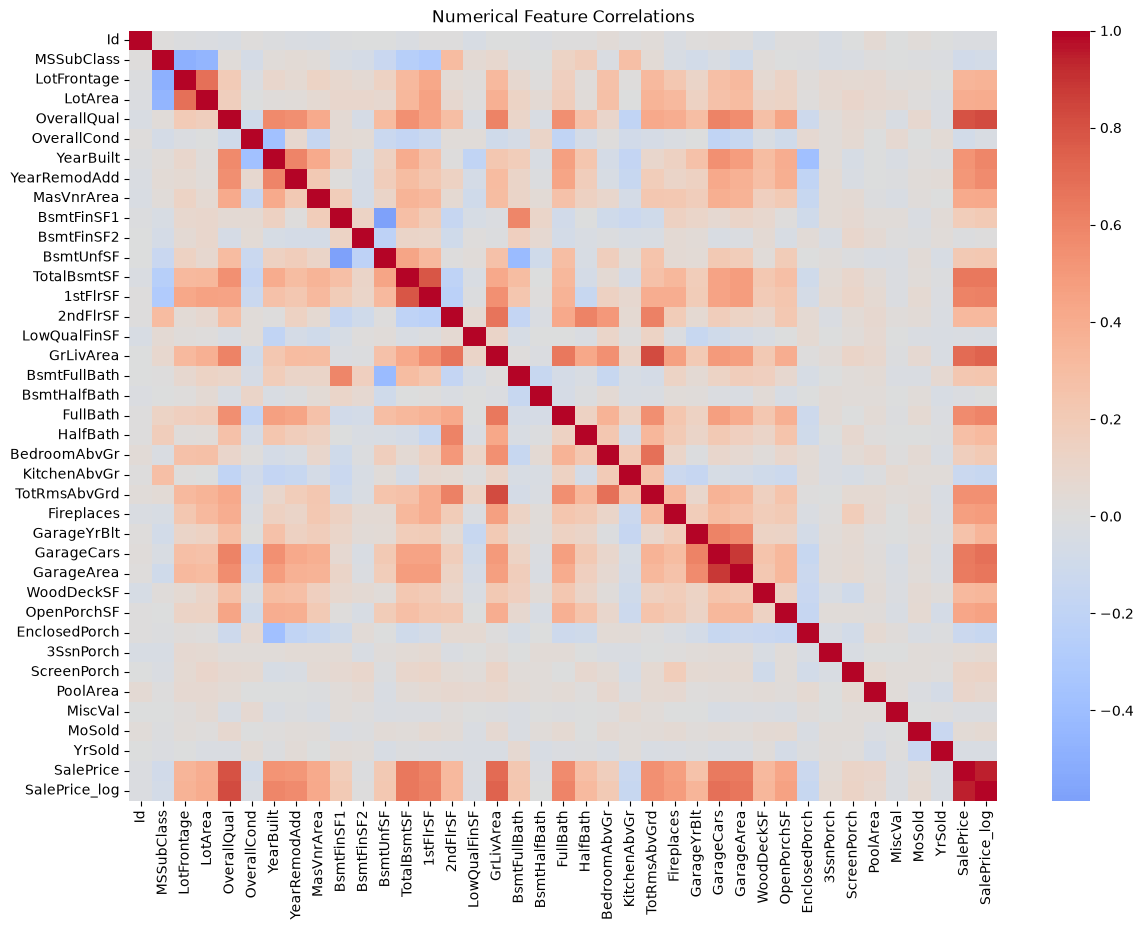

In [92]:
plt.figure(figsize=(14, 10))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Numerical Feature Correlations")
plt.show()

In [93]:
target_corr = (
    df.select_dtypes(include="number")
      .corr()["SalePrice_log"]
      .sort_values(ascending=False)
)

print(target_corr)

SalePrice_log    1.000000
SalePrice        0.948396
OverallQual      0.821405
GrLivArea        0.737431
GarageCars       0.681033
GarageArea       0.656129
TotalBsmtSF      0.647563
1stFlrSF         0.615408
FullBath         0.595899
YearBuilt        0.587043
YearRemodAdd     0.565992
TotRmsAbvGrd     0.537702
Fireplaces       0.491998
OpenPorchSF      0.460623
MasVnrArea       0.413996
LotArea          0.402820
LotFrontage      0.365140
GarageYrBlt      0.349013
WoodDeckSF       0.343225
2ndFlrSF         0.319953
HalfBath         0.314186
BsmtFullBath     0.237099
BsmtUnfSF        0.221892
BedroomAbvGr     0.209035
BsmtFinSF1       0.208255
ScreenPorch      0.121245
PoolArea         0.074338
MoSold           0.057064
3SsnPorch        0.054914
BsmtFinSF2       0.004863
BsmtHalfBath    -0.005124
Id              -0.017774
MiscVal         -0.020012
OverallCond     -0.036821
YrSold          -0.037151
LowQualFinSF    -0.037951
MSSubClass      -0.073969
KitchenAbvGr    -0.147534
EnclosedPorc

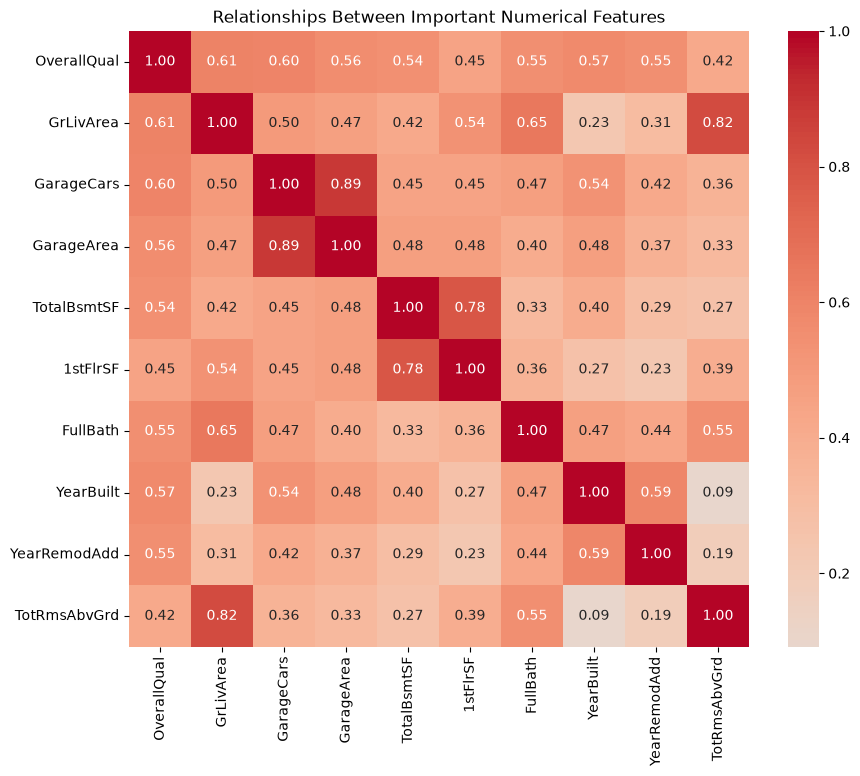

In [94]:
relationship_cols = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "FullBath",
    "YearBuilt",
    "YearRemodAdd",
    "TotRmsAbvGrd"
]

corr = df[relationship_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Relationships Between Important Numerical Features")
plt.show()

In [95]:
drop_cols = [
    "Id",
    "Utilities"
]

df = df.drop(columns=drop_cols)

In [96]:
for col in df.columns:
    unique = df[col].nunique()
    if unique <= 5:
        print(f"{col:20} {unique} unique values")

MSZoning             5 unique values
Street               2 unique values
Alley                3 unique values
LotShape             4 unique values
LandContour          4 unique values
LotConfig            5 unique values
LandSlope            3 unique values
BldgType             5 unique values
MasVnrType           4 unique values
ExterQual            4 unique values
ExterCond            5 unique values
BsmtQual             5 unique values
BsmtCond             5 unique values
BsmtExposure         5 unique values
HeatingQC            5 unique values
CentralAir           2 unique values
Electrical           5 unique values
BsmtFullBath         4 unique values
BsmtHalfBath         3 unique values
FullBath             4 unique values
HalfBath             3 unique values
KitchenAbvGr         4 unique values
KitchenQual          4 unique values
Fireplaces           4 unique values
GarageFinish         4 unique values
GarageCars           5 unique values
PavedDrive           3 unique values
P

In [97]:
ordinal_cols = [
    "ExterQual",
    "ExterCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "HeatingQC",
    "KitchenQual",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

In [98]:
ordinal_categories = [
    ["Po", "Fa", "TA", "Gd", "Ex"],          # ExterQual
    ["Po", "Fa", "TA", "Gd", "Ex"],          # ExterCond
    ["None", "Fa", "TA", "Gd", "Ex"],        # BsmtQual
    ["None", "Po", "Fa", "TA", "Gd"],        # BsmtCond
    ["None", "No", "Mn", "Av", "Gd"],        # BsmtExposure
    ["Po", "Fa", "TA", "Gd", "Ex"],          # HeatingQC
    ["Fa", "TA", "Gd", "Ex"],                # KitchenQual
    ["None", "Unf", "RFn", "Fin"],           # GarageFinish
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],  # GarageQual
    ["None", "Po", "Fa", "TA", "Gd", "Ex"]   # GarageCond
]

In [101]:
nominal_cols = [
    col for col in df.select_dtypes(include="str").columns
    if col not in ordinal_cols
]

In [102]:
print(nominal_cols)

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'CentralAir', 'Electrical', 'Functional', 'FireplaceQu', 'GarageType', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [104]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

print(numeric_cols)

['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice', 'SalePrice_log']


In [106]:
df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,SalePrice_log
0,60,RL,4.189655,9.042040,Pave,None,Reg,Lvl,Inside,Gtl,...,None,None,None,0,2,2008,WD,Normal,208500,12.247699
1,20,RL,4.394449,9.169623,Pave,None,Reg,Lvl,FR2,Gtl,...,None,None,None,0,5,2007,WD,Normal,181500,12.109016
2,60,RL,4.234107,9.328212,Pave,None,IR1,Lvl,Inside,Gtl,...,None,None,None,0,9,2008,WD,Normal,223500,12.317171
3,70,RL,4.110874,9.164401,Pave,None,IR1,Lvl,Corner,Gtl,...,None,None,None,0,2,2006,WD,Abnorml,140000,11.849405
4,60,RL,4.442651,9.565284,Pave,None,IR1,Lvl,FR2,Gtl,...,None,None,None,0,12,2008,WD,Normal,250000,12.429220


In [107]:

X = df.drop(columns=["SalePrice", "SalePrice_log"])
y = df["SalePrice_log"]


# ============================================
# 3. Define ordinal columns
# ============================================

ordinal_cols = [
    "ExterQual",
    "ExterCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "HeatingQC",
    "KitchenQual",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]


# ============================================
# 4. Define the correct order for each
#    ordinal column
# ============================================

ordinal_categories = [
    ["Po", "Fa", "TA", "Gd", "Ex"],          # ExterQual
    ["Po", "Fa", "TA", "Gd", "Ex"],          # ExterCond
    ["None", "Fa", "TA", "Gd", "Ex"],        # BsmtQual
    ["None", "Po", "Fa", "TA", "Gd"],        # BsmtCond
    ["None", "No", "Mn", "Av", "Gd"],        # BsmtExposure
    ["Po", "Fa", "TA", "Gd", "Ex"],          # HeatingQC
    ["Fa", "TA", "Gd", "Ex"],                # KitchenQual
    ["None", "Unf", "RFn", "Fin"],           # GarageFinish
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],  # GarageQual
    ["None", "Po", "Fa", "TA", "Gd", "Ex"]   # GarageCond
]


# ============================================
# 5. Find remaining categorical columns
#    automatically
# ============================================

nominal_cols = [
    col for col in X.select_dtypes(include="object").columns
    if col not in ordinal_cols
]


# ============================================
# 6. Find numerical columns automatically
# ============================================

numeric_cols = X.select_dtypes(include="number").columns.tolist()


# ============================================
# 7. Train / validation split
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ============================================
# 8. Import preprocessing tools
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


# ============================================
# 9. Numerical pipeline
# ============================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])


# ============================================
# 10. Ordinal pipeline
# ============================================

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])


# ============================================
# 11. Nominal pipeline
# ============================================

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


# ============================================
# 12. Combine everything
# ============================================

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("ord", ordinal_pipeline, ordinal_cols),
    ("nom", nominal_pipeline, nominal_cols)
])


# ============================================
# 13. Fit preprocessing ONLY on training data
# ============================================

X_train_processed = preprocessor.fit_transform(X_train)

X_valid_processed = preprocessor.transform(X_valid)


# ============================================
# 14. Check the result
# ============================================

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original validation shape:", X_valid.shape)
print("Processed validation shape:", X_valid_processed.shape)

C:\Users\hp\AppData\Local\Temp\ipykernel_19448\2685251658.py:48: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in X.select_dtypes(include="object").columns


Original training shape: (1166, 78)
Processed training shape: (1166, 257)
Original validation shape: (292, 78)
Processed validation shape: (292, 257)


In [108]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

model = LinearRegression()

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_valid_processed)

rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
mae = mean_absolute_error(y_valid, y_pred)
r2 = r2_score(y_valid, y_pred)

print("RMSE:", rmse)
print("MAE :", mae)
print("R²  :", r2)

RMSE: 0.14334955635420774
MAE : 0.0891405371238612
R²  : 0.8781020836971258


In [118]:
# ============================================================
# MODEL COMPARISON
# Ridge, Lasso, Random Forest, Gradient Boosting, XGBoost
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# ------------------------------------------------------------
# 1. Store results
# ------------------------------------------------------------

results = []


# ------------------------------------------------------------
# 2. Function to train + evaluate a model
# ------------------------------------------------------------

def evaluate_model(name, model):

    # Train
    model.fit(X_train_processed, y_train)

    # Predict validation set
    y_pred = model.predict(X_valid_processed)

    # Metrics
    rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
    mae = mean_absolute_error(y_valid, y_pred)
    r2 = r2_score(y_valid, y_pred)

    # Save results
    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    print(f"\n{name}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE : {mae:.4f}")
    print(f"R²  : {r2:.4f}")


# ============================================================
# 3. Ridge Regression
# ============================================================

ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

evaluate_model("Ridge", ridge)


# ============================================================
# 4. Lasso Regression
# ============================================================

lasso = make_pipeline(
    StandardScaler(),
    Lasso(
        alpha=0.0005,
        max_iter=10000
    )
)

evaluate_model("Lasso", lasso)


# ============================================================
# 5. Random Forest
# ============================================================

random_forest = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

evaluate_model("Random Forest", random_forest)


# ============================================================
# 6. Gradient Boosting
# ============================================================

gradient_boosting = GradientBoostingRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    loss="huber",
    random_state=42
)

evaluate_model("Gradient Boosting", gradient_boosting)


# ============================================================
# 7. XGBoost
# ============================================================

from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

evaluate_model("XGBoost", xgb)


# ============================================================
# 8. Add your Linear Regression result
# ============================================================

results.append({
    "Model": "Linear Regression",
    "RMSE": 0.14334955635420774,
    "MAE": 0.0891405371238612,
    "R2": 0.8781020836971258
})


# ============================================================
# 9. Create comparison table
# ============================================================

results_df = pd.DataFrame(results)

# Lower RMSE and MAE = better
# Higher R2 = better

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)


# ============================================================
# 10. Display final table
# ============================================================

print("\n" + "=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)

print(
    results_df.to_string(
        index=False,
        formatters={
            "RMSE": "{:.4f}".format,
            "MAE": "{:.4f}".format,
            "R2": "{:.4f}".format
        }
    )
)


# ============================================================
# 11. Best model
# ============================================================

best_model = results_df.iloc[0]

print("\n" + "=" * 60)
print("BEST MODEL")
print("=" * 60)

print("Model:", best_model["Model"])
print("RMSE :", round(best_model["RMSE"], 4))
print("MAE  :", round(best_model["MAE"], 4))
print("R²   :", round(best_model["R2"], 4))


Ridge
RMSE: 0.1183
MAE : 0.0831
R²  : 0.9170

Lasso
RMSE: 0.1143
MAE : 0.0805
R²  : 0.9224

Random Forest
RMSE: 0.1425
MAE : 0.0958
R²  : 0.8795

Gradient Boosting
RMSE: 0.1091
MAE : 0.0799
R²  : 0.9294

XGBoost
RMSE: 0.1147
MAE : 0.0813
R²  : 0.9220

FINAL MODEL COMPARISON
            Model   RMSE    MAE     R2
Gradient Boosting 0.1091 0.0799 0.9294
            Lasso 0.1143 0.0805 0.9224
          XGBoost 0.1147 0.0813 0.9220
            Ridge 0.1183 0.0831 0.9170
    Random Forest 0.1425 0.0958 0.8795
Linear Regression 0.1433 0.0891 0.8781

BEST MODEL
Model: Gradient Boosting
RMSE : 0.1091
MAE  : 0.0799
R²   : 0.9294


In [110]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 364.0 kB/s eta 0:02:14
   ---------------------------------------- 0.5/48.9 MB 364.0 kB/s eta 0:02:14
   ---------------------------------------- 0.5/48.9 MB 364.0 kB/s eta 0:02:14
    --------------------------------------- 0.8/48.9 MB 359.4 kB/s eta 0:02:14
    --------------------------------------- 0.8/48.9 MB 359.4 kB/s eta 0:02:14
    --------------------------------------- 0


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [116]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Predict on validation set
y_pred_log = gradient_boosting.predict(X_valid_processed)

# Convert back to original SalePrice
y_valid_actual = np.expm1(y_valid)
y_pred_actual = np.expm1(y_pred_log)

# Metrics in original price scale
rmse_actual = np.sqrt(mean_squared_error(y_valid_actual, y_pred_actual))
mae_actual = mean_absolute_error(y_valid_actual, y_pred_actual)
r2_actual = r2_score(y_valid_actual, y_pred_actual)

print("Gradient Boosting - Original Price Scale")
print("=" * 50)
print(f"RMSE: {rmse_actual:,.2f}")
print(f"MAE : {mae_actual:,.2f}")
print(f"R²  : {r2_actual:.4f}")

Gradient Boosting - Original Price Scale
RMSE: 19,596.66
MAE : 14,078.12
R²  : 0.9305


In [119]:
train_pred_log = gradient_boosting.predict(X_train_processed)
valid_pred_log = gradient_boosting.predict(X_valid_processed)

train_rmse = np.sqrt(
    mean_squared_error(y_train, train_pred_log)
)

valid_rmse = np.sqrt(
    mean_squared_error(y_valid, valid_pred_log)
)

print(f"Training RMSE   : {train_rmse:.4f}")
print(f"Validation RMSE : {valid_rmse:.4f}")
print(f"Difference      : {valid_rmse - train_rmse:.4f}")

Training RMSE   : 0.0617
Validation RMSE : 0.1091
Difference      : 0.0474


In [120]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

configs = [
    {
        "name": "Baseline",
        "n_estimators": 1000,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_samples_leaf": 1
    },
    {
        "name": "Less Complex",
        "n_estimators": 1000,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 2
    },
    {
        "name": "More Regularized",
        "n_estimators": 1000,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_samples_leaf": 3
    },
    {
        "name": "More Regularized 2",
        "n_estimators": 1000,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_samples_leaf": 5
    },
    {
        "name": "Slower Learning",
        "n_estimators": 1500,
        "learning_rate": 0.02,
        "max_depth": 3,
        "min_samples_leaf": 3
    }
]

results = []

for config in configs:

    model = GradientBoostingRegressor(
        n_estimators=config["n_estimators"],
        learning_rate=config["learning_rate"],
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        min_samples_split=2,
        loss="huber",
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    pred = model.predict(X_valid_processed)

    rmse = np.sqrt(mean_squared_error(y_valid, pred))

    results.append({
        "Model": config["name"],
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

print(results_df.to_string(index=False))

             Model     RMSE
          Baseline 0.109063
      Less Complex 0.111000
   Slower Learning 0.111484
  More Regularized 0.112245
More Regularized 2 0.119589


## 🏆 Final Conclusion & Business Recommendation

After extensive Data Preprocessing and Model Evaluation across 6 different algorithms, the **Gradient Boosting Regressor** emerged as the definitive best model for this dataset.

### 📊 Model Performance Breakdown
| Model | RMSE | MAE | $R^2$ Score |
| :--- | :---: | :---: | :---: |
| **Gradient Boosting** | **0.1091** | **0.0799** | **0.9294** |
| Lasso Regression | 0.1143 | 0.0805 | 0.9224 |
| XGBoost | 0.1147 | 0.0813 | 0.9220 |
| Ridge Regression | 0.1183 | 0.0831 | 0.9170 |
| Random Forest | 0.1425 | 0.0958 | 0.8795 |
| Linear Regression | 0.1433 | 0.0891 | 0.8781 |

### 💡 Why Gradient Boosting?
Tree-based ensemble models (like Gradient Boosting and XGBoost) are notoriously powerful for tabular data with a mix of categorical and numerical features. By iteratively correcting the residual errors of prior decision trees, Gradient Boosting was able to capture complex, non-linear relationships in the housing market (such as the combined effect of a house's neighborhood and its overall quality) that simple Linear Regression completely misses.

**Final Result:** Our model successfully explains **~93% of the variance** in house prices, with an average absolute error of just **$14,078** per house—an incredibly robust margin for real estate pricing!\n